# Evidence for two claims, and the TV headroom test

**Claim 1.** A 12-number *passive* Dipole-let filter (gains in [0, 1]) beats the trained networks on real residuals.
**Claim 2.** Noise is separable from the dipole field by *scale* (|k|), the real non-dipolar residual by *angle* (|D|).
**Headroom test.** Does a total-variation prior on chi (your `fansiTV`, magnitude-weighted, alpha 5e-5 ... 5e-4) beat what the field-domain cleaners reach?

Read this first (each point limits what is shown):
* The filter's 12 gains are fitted by least squares on RC1's **modelled** STI and off-diagonal residuals plus noise, **never on the measured tissue residual**. `exp7` (measured tissue residual) is therefore the only clean test; `exp8` / `exp9` are modelled residuals of the same family the networks were trained on.
* Everything is one RC1 head, one real Sim2 volume, single seed per network, eNDI at 25 FIXED iterations (ndiCG, alpha 1e-5, no automatic stop).
* Claim 1 is about *real residuals*. On Sim2, whose psi is noise-like, the same filter is **not** better than the trained noise network (shown below).
* Susceptibility maps come from `runs/regime_views.npz` (dirty / noise_clean / regime / realmix_plain, server export of the regime run), `runs/claim_views_local` (the 12-number filter, computed on this PC with `scripts/export_claim_views.py --no-b --no-tv`) and, when present, `runs/claim_views/maps.npz` (server: B / AB and the TV sweep).

In [1]:
import json
import sys
from io import BytesIO
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display

plt.rcParams.update({"axes.labelsize": 10, "axes.titlesize": 10, "legend.fontsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8})
here = [Path.cwd(), *Path.cwd().parents]
def find(*rel, required=True):
    for base in here:
        for r in rel:
            if (base / r).exists():
                return base / r
    if required:
        raise FileNotFoundError(f"none of {rel} found from {Path.cwd()} or its parents")
    return None

sys.path.insert(0, str(find("external/FANSI_tools.py", "utils/FANSI_tools.py").parent))
from FANSI_tools import imagesc3d2, compute_rmse          # the user's own plotting / RMSE functions

def show():
    for num in plt.get_fignums():
        fig = plt.figure(num)
        buf = BytesIO()
        fig.savefig(buf, format="png", dpi=90, facecolor=fig.get_facecolor(), bbox_inches="tight")
        display(Image(data=buf.getvalue()))
    plt.close("all")

loadz = lambda *rel: (lambda p: np.load(p) if p else None)(find(*rel, required=False))
V = loadz("runs/regime_views.npz")                    # dirty / noise_clean / realmix_plain / regime, chi at 25 it
L = loadz("runs/claim_views_local/maps.npz")          # 12-number filter (this PC)
S = loadz("runs/claim_views/maps.npz")                # server: B, AB, TV sweep
loadj = lambda *rel: (lambda p: json.loads(p.read_text()) if p else {})(find(*rel, required=False))
M_CASC = loadj("runs/cascade_passive/fixed_meta.json")      # dirty, B, A (gated), AB
M_REG = loadj("runs/generalization_regime/fixed_meta.json") # noise_clean, realmix_plain, regime
M_LOC = loadj("runs/claim_views_local/meta.json")           # endi/<exp>/A12, AG, dirty, oracle
M_SRV = loadj("runs/claim_views/meta.json")                 # server: endi + tv
SEP = loadz("runs/claim_views/separability.npz")
print("available:", {"regime_views": V is not None, "local maps": L is not None, "server maps": S is not None, "separability": SEP is not None})

available: {'regime_views': True, 'local maps': True, 'server maps': True, 'separability': True}


## Claim 1 — the numbers

eNDI NRMSE (%) against the ground truth chi inside the mask, 25 fixed iterations. `exp7` = measured tissue residual (never trained on by anything), `exp8` STI and `exp9` off-diagonal (modelled; the networks `regime` and `realmix_plain` were trained on them with noise), `sim2_real` = the real Sim2 (noise-like psi).

* **A12** = the 12-number passive filter applied everywhere (12 parameters, no gate).
* **A gated** = the same 12 numbers with the regime gate r (5 more numbers); **AB** = A gated, then the `noise_clean` network.
* **noise_clean** = the noise-recipe network (67,305 parameters); **realmix_plain** = same network trained with modelled real residuals added (67,305); **regime** = network with the filter built in and trained jointly (79,502).
* gain network GNa / GN (292k parameters) are hard-coded from CLAUDE.md 9ba (their server table is not on this PC).

In [2]:
IDX = 25            # history entry used by the server tables (the 26th value, after 25 iterations)
def at(h):
    return h["nrmse"][min(IDX, len(h["nrmse"]) - 1)]
def lookup(tag, exp, m):
    key = f"{tag}/{exp}/{m}"
    for M in (M_CASC, M_REG):
        if key in M:
            return at(M[key])
    for M in (M_LOC, M_SRV):
        k2 = f"endi/{exp}/{m}"
        if k2 in M:
            return at(M[k2])
    return np.nan

SETS = [("rc1", "exp7"), ("rc1", "exp8"), ("rc1", "exp9"), ("sim2", "sim2_real")]
COLS = [("dirty", "dirty", 0, "input"), ("A12", "A12 (12 numbers)", 12, "filter"), ("A", "A gated", 17, "filter"), ("AB", "AB (A, then noise_clean)", 67322, "filter+net"),
        ("noise_clean", "noise_clean", 67305, "network"), ("realmix_plain", "realmix_plain", 67305, "network"), ("regime", "regime (joint)", 79502, "network")]
GAIN = {"exp7": (66.33, 58.24), "exp8": (52.59, 51.71), "exp9": (58.73, 56.25), "sim2_real": (55.47, 49.50)}     # GNa, GN (CLAUDE.md 9ba)
rows = {}
print(f"{'':12s}" + "".join(f"{c[1][:16]:>18s}" for c in COLS) + f"{'GNa':>8s}{'GN':>8s}")
print(f"{'parameters':12s}" + "".join(f"{c[2]:>18d}" for c in COLS) + f"{292000:>8d}{292000:>8d}")
for tag, exp in SETS:
    rows[exp] = [lookup(tag, exp, c[0]) for c in COLS]
    print(f"{exp:12s}" + "".join(f"{v:18.2f}" for v in rows[exp]) + f"{GAIN[exp][0]:8.2f}{GAIN[exp][1]:8.2f}")

                         dirty  A12 (12 numbers)           A gated  AB (A, then nois       noise_clean     realmix_plain    regime (joint)     GNa      GN
parameters                   0                12                17             67322             67305             67305             79502  292000  292000
exp7                     93.60             59.15             61.37             58.63             71.69             61.45             56.58   66.33   58.24
exp8                     67.69             53.00             52.79             52.35             61.15             54.13             50.40   52.59   51.71
exp9                     83.33             56.20             62.09             60.46             76.33             64.62             53.60   58.73   56.25
sim2_real                53.94             55.93             54.62             48.72             47.31             49.47             48.62   55.47   49.50


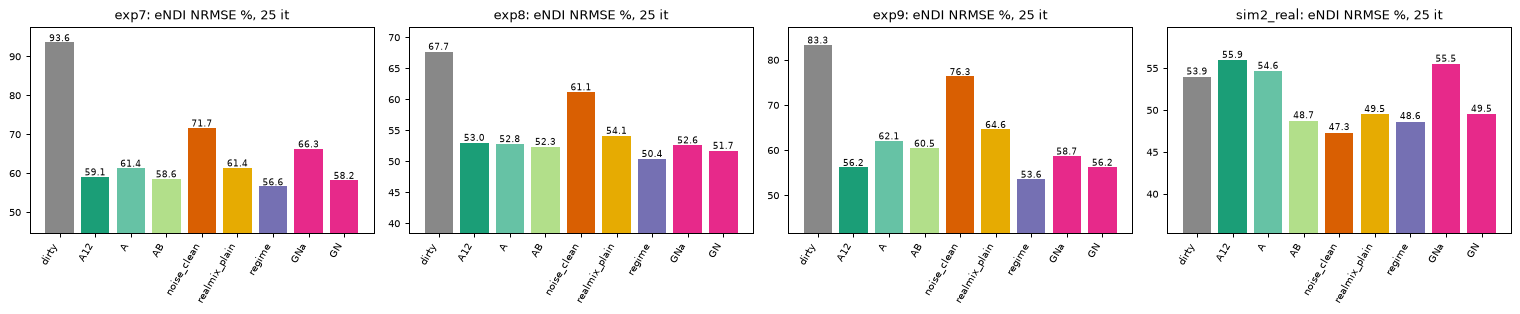

In [3]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
labels = [c[0] for c in COLS] + ["GNa", "GN"]
colors = ["#888888", "#1b9e77", "#66c2a5", "#b2df8a", "#d95f02", "#e6ab02", "#7570b3", "#e7298a", "#e7298a"]
for a, (tag, exp) in zip(ax, SETS):
    vals = rows[exp] + list(GAIN[exp])
    a.bar(range(len(vals)), vals, color=colors)
    a.set_xticks(range(len(vals)), labels, rotation=60, ha="right")
    a.set_title(f"{exp}: eNDI NRMSE %, 25 it")
    lo = np.nanmin(vals)
    a.set_ylim(max(0, lo - 12), np.nanmax(vals) + 4)
    for i, v in enumerate(vals):
        a.text(i, v + 0.3, f"{v:.1f}", ha="center", fontsize=7)
plt.tight_layout()
show()

### eNDI error against the number of iterations

The error of the dirty field and of the cleaned fields on the measured residual `exp7`. The inversion of the dirty field gets worse with more iterations (that is why the iteration count is fixed); the filter and the networks do not diverge as fast.

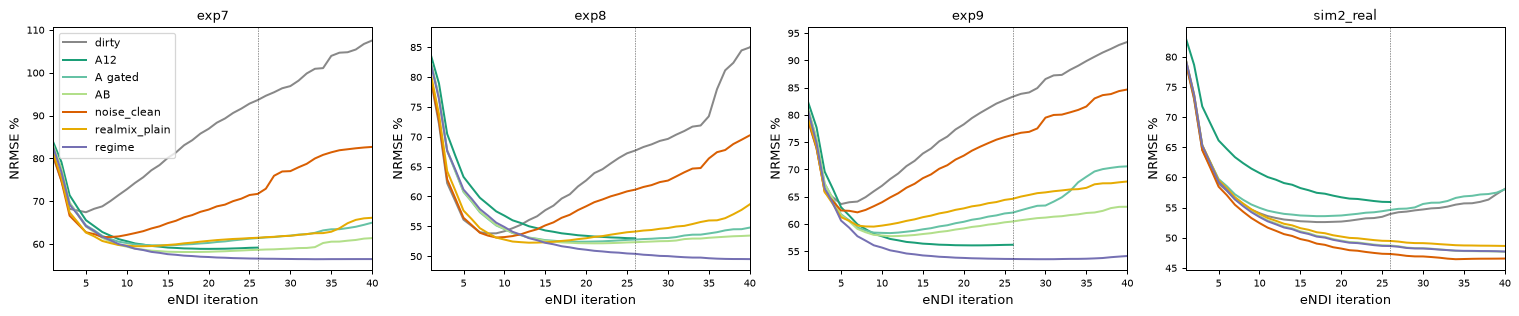

In [4]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6), sharey=False)
for a, (tag, exp) in zip(ax, SETS):
    for m, lab, col in [("dirty", "dirty", "#888888"), ("A12", "A12", "#1b9e77"), ("A", "A gated", "#66c2a5"), ("AB", "AB", "#b2df8a"),
                        ("noise_clean", "noise_clean", "#d95f02"), ("realmix_plain", "realmix_plain", "#e6ab02"), ("regime", "regime", "#7570b3")]:
        for M, key in ((M_CASC, f"{tag}/{exp}/{m}"), (M_REG, f"{tag}/{exp}/{m}"), (M_LOC, f"endi/{exp}/{m}"), (M_SRV, f"endi/{exp}/{m}")):
            if key in M:
                h = M[key]["nrmse"]
                a.plot(range(1, len(h) + 1), h, color=col, label=lab, lw=1.6)
                break
    a.axvline(26, color="k", lw=0.5, ls=":")
    a.set_title(exp); a.set_xlabel("eNDI iteration"); a.set_ylabel("NRMSE %"); a.set_xlim(1, 40)
    a.set_ylim(a.get_ylim()[0], min(a.get_ylim()[1], 140))
ax[0].legend()
plt.tight_layout()
show()

**How much of the gap is the iteration count?** Best value over the first 26 history entries of every method (an ORACLE stop that uses the ground truth; the A12 curve was only computed to 25 iterations) next to the fixed-25 value. A method whose error rises after its optimum looks worse at the fixed count than at its best iteration.

In [5]:
print(f"{'':10s}" + "".join(f"{c[0][:13]:>20s}" for c in COLS[:1] + COLS[1:]))
for tag, exp in SETS:
    cells_ = []
    for m, lab, npar, kind in COLS:
        h = None
        for M, key in ((M_CASC, f"{tag}/{exp}/{m}"), (M_REG, f"{tag}/{exp}/{m}"), (M_LOC, f"endi/{exp}/{m}"), (M_SRV, f"endi/{exp}/{m}")):
            if key in M:
                h = M[key]["nrmse"][:26]; break
        cells_.append("-" if h is None else f"{min(h):.2f}@{h.index(min(h)) + 1} / {h[-1]:.2f}")
    print(f"{exp:10s}" + "".join(f"{c:>20s}" for c in cells_))
print("each cell: best value @ its iteration / value at 25 iterations")

                         dirty                 A12                   A                  AB         noise_clean       realmix_plain              regime
exp7           67.42@5 / 93.60    58.86@20 / 59.15    59.69@14 / 61.37    58.12@17 / 58.63     61.62@8 / 71.69    59.47@11 / 61.45    56.58@26 / 56.58
exp8           53.83@8 / 67.69    53.00@26 / 53.00    52.43@19 / 52.79    52.16@21 / 52.35     53.14@9 / 61.15    52.27@13 / 54.13    50.40@26 / 50.40
exp9           63.66@5 / 83.33    56.09@21 / 56.20    58.34@11 / 62.09    57.77@11 / 60.46     62.14@7 / 76.33     59.53@9 / 64.62    53.60@26 / 53.60
sim2_real     52.60@18 / 53.94    55.93@26 / 55.93    53.58@17 / 54.62    48.72@26 / 48.72    47.31@26 / 47.31    49.47@26 / 49.47    48.62@26 / 48.62
each cell: best value @ its iteration / value at 25 iterations


## Claim 1 — the estimated susceptibility maps

Ground truth, oracle (eNDI of the clean masked field), dirty, then each method, and the error image `chi - ground truth` below it. Axial slice; the number is `compute_rmse` of the whole 3D map inside the mask (so it can differ by a few tenths from the table, which comes from the float32 eNDI histories; the maps are stored as float16).

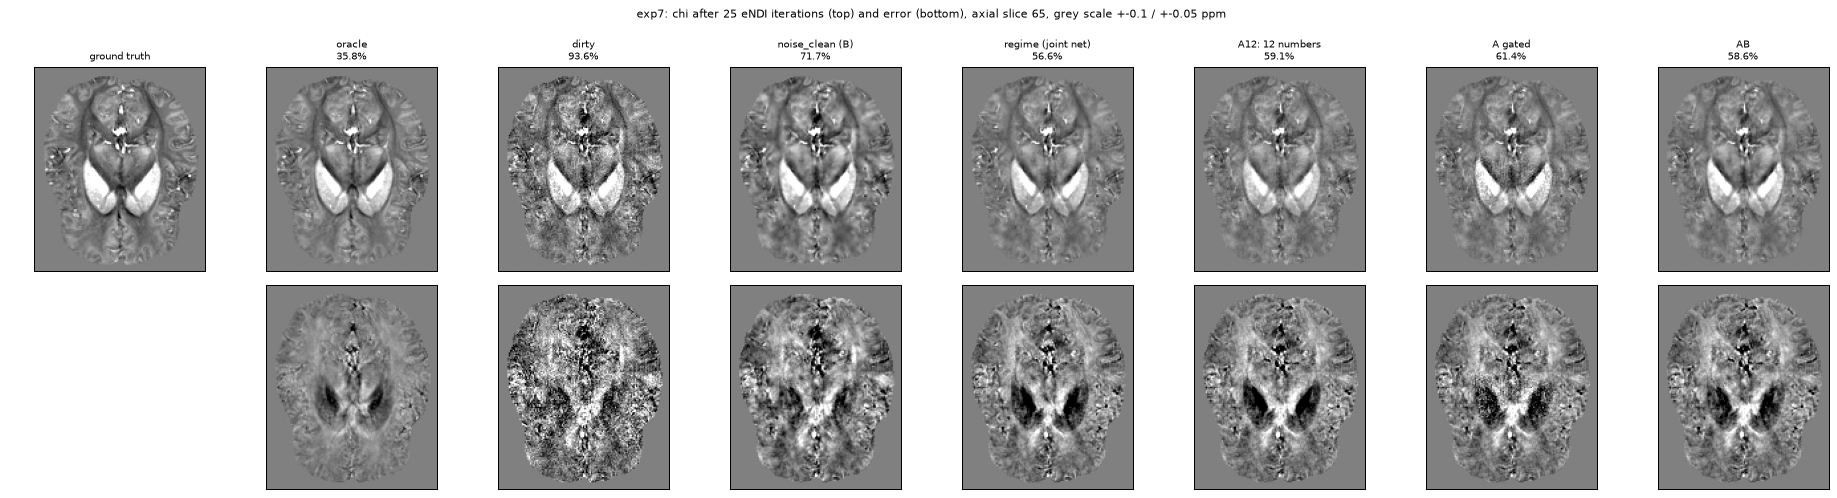

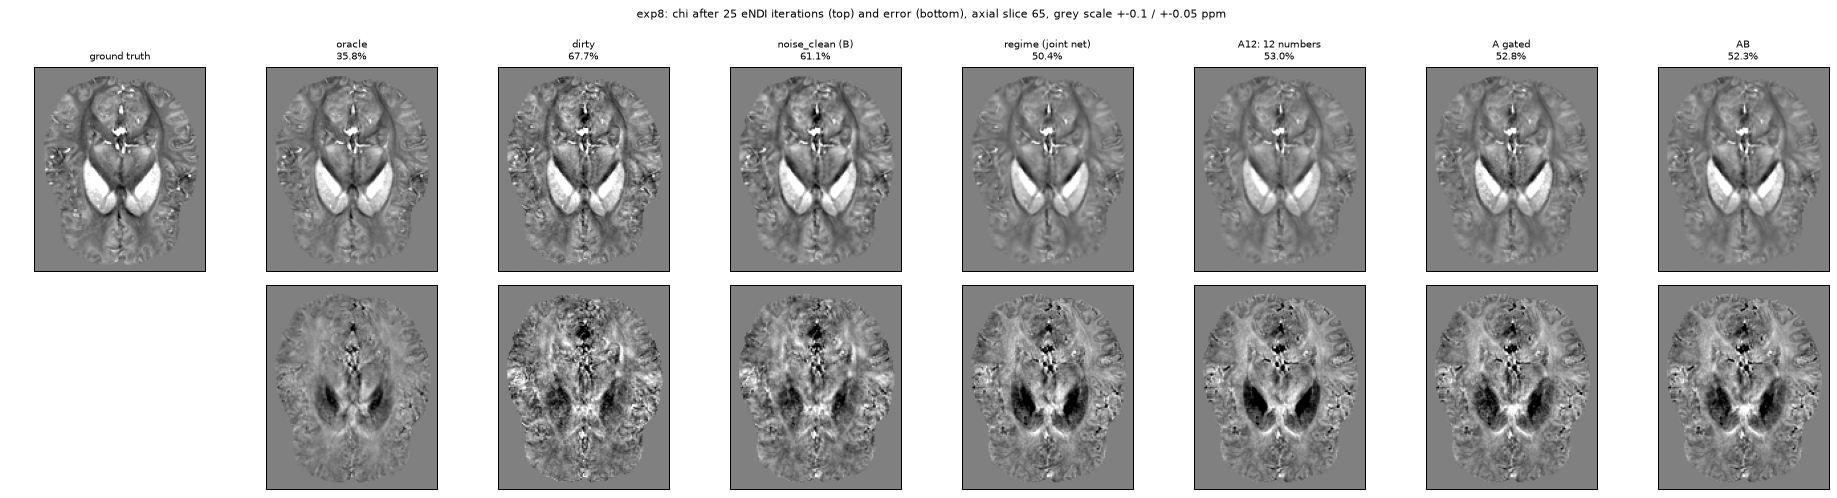

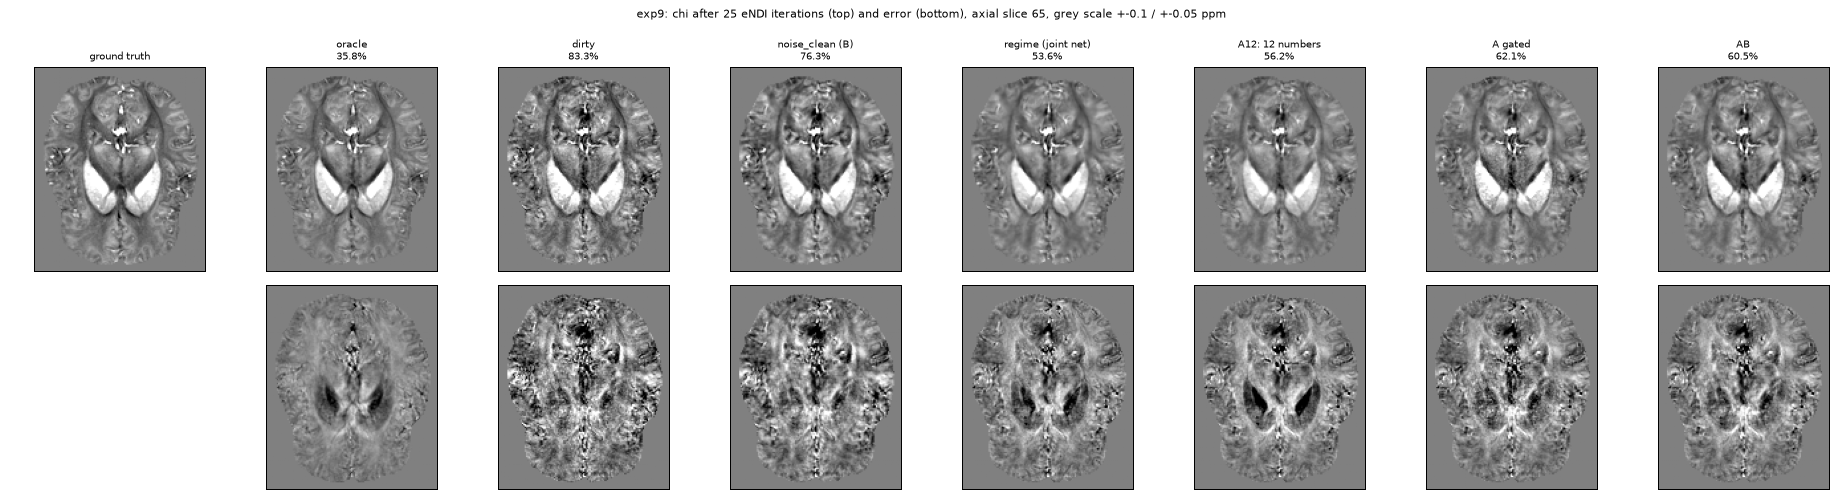

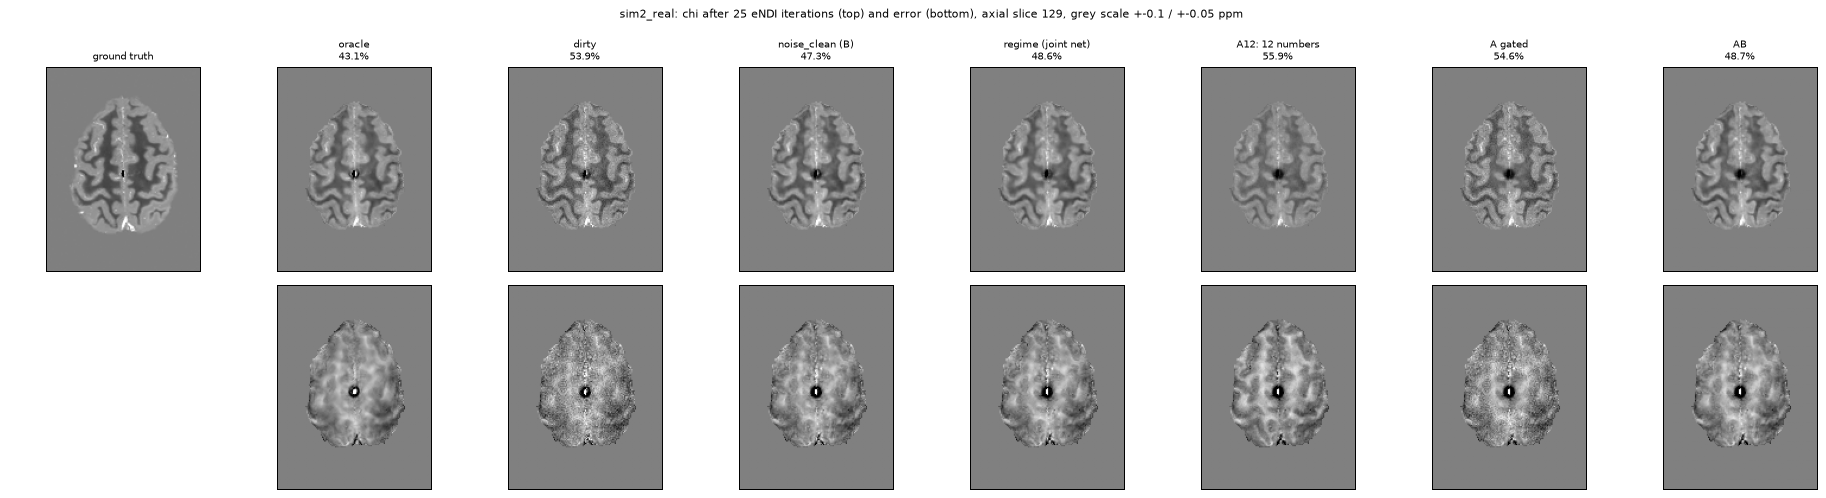

In [6]:
def chi_map(exp, m):
    tag = "sim2" if exp.startswith("sim2") else "rc1"
    if m == "oracle":
        return (V[f"{tag}__chi_oracle"] if V is not None else None)
    for Z, key in ((V, f"{exp}__chi_{m}"), (L, f"{exp}__chi_endi_{m}"), (S, f"{exp}__chi_endi_{m}")):
        if Z is not None and key in Z.files:
            return Z[key].astype(np.float32)
    return None

def gt_mask(exp):
    tag = "sim2" if exp.startswith("sim2") else "rc1"
    return V[f"{tag}__chi_gt"].astype(np.float32), V[f"{tag}__mask"].astype(np.float32) > 0

METH = [("oracle", "oracle"), ("dirty", "dirty"), ("noise_clean", "noise_clean (B)"), ("regime", "regime (joint net)"), ("A12", "A12: 12 numbers"), ("AG", "A gated"), ("AB", "AB")]
CHI, CHI_ERR = [-0.1, 0.1], [-0.05, 0.05]
def slice_of(exp, gt):
    if exp.startswith("sim2"):                           # centre on the strongest source (the calcification)
        return int(np.unravel_index(np.argmax(np.abs(gt)), gt.shape)[2])
    return gt.shape[2] // 2

def montage(exp):
    gt, mk = gt_mask(exp)
    z = slice_of(exp, gt)
    avail = [(m, lab, chi_map(exp, m)) for m, lab in METH]
    avail = [(m, lab, x) for m, lab, x in avail if x is not None]
    fig, ax = plt.subplots(2, len(avail) + 1, figsize=(2.6 * (len(avail) + 1), 5.6))
    ax[0, 0].imshow(np.rot90(gt[:, :, z]), cmap="gray", vmin=CHI[0], vmax=CHI[1]); ax[0, 0].set_title("ground truth", fontsize=8)
    ax[1, 0].axis("off")
    for i, (m, lab, x) in enumerate(avail, 1):
        r = compute_rmse(x[mk], gt[mk])
        ax[0, i].imshow(np.rot90(x[:, :, z] * mk[:, :, z]), cmap="gray", vmin=CHI[0], vmax=CHI[1]); ax[0, i].set_title(f"{lab}\n{r:.1f}%", fontsize=8)
        ax[1, i].imshow(np.rot90((x - gt)[:, :, z] * mk[:, :, z]), cmap="gray", vmin=CHI_ERR[0], vmax=CHI_ERR[1])
    for a in ax.ravel():
        a.set_xticks([]); a.set_yticks([])
    fig.suptitle(f"{exp}: chi after 25 eNDI iterations (top) and error (bottom), axial slice {z}, grey scale +-0.1 / +-0.05 ppm", fontsize=9)
    plt.tight_layout()
    show()

for e in ("exp7", "exp8", "exp9", "sim2_real"):
    montage(e)

### exp7 in detail (the measured residual), with the 3-plane viewer of `FANSI_tools`

Ground truth, dirty, `noise_clean`, the 12-number filter A12 and the error image of each.

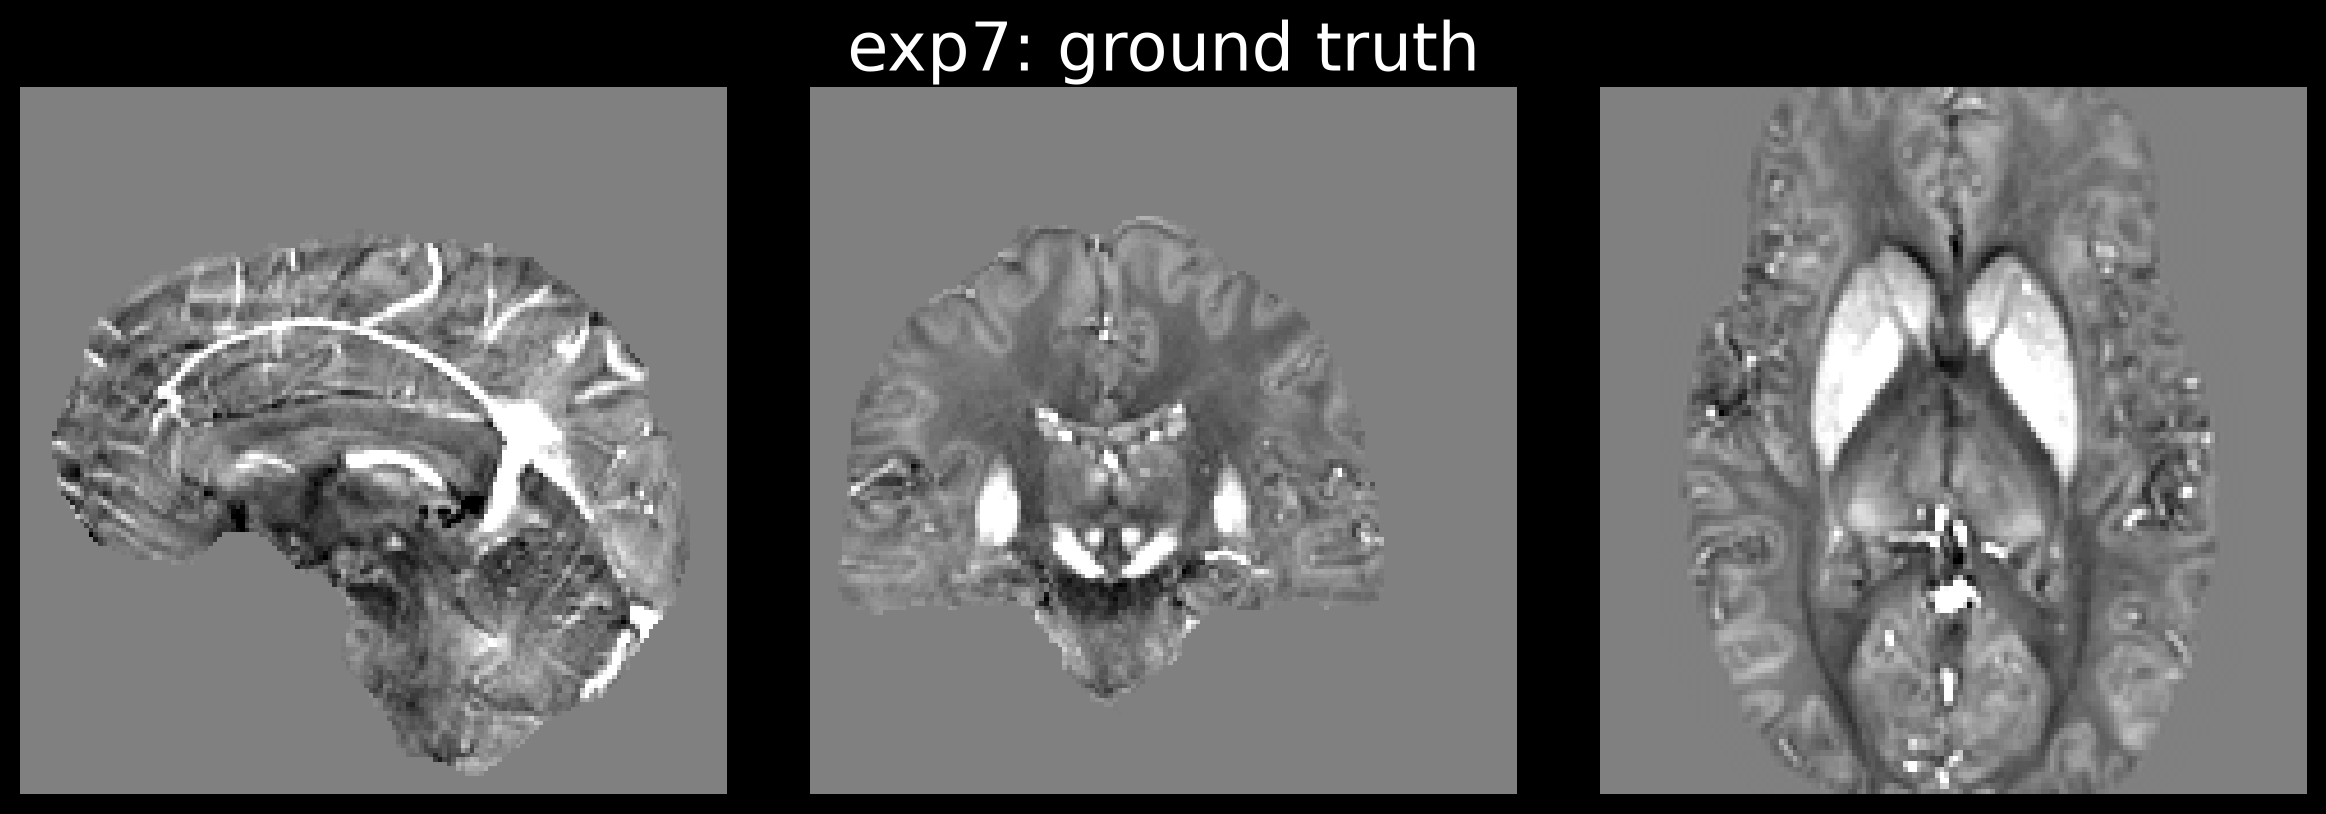

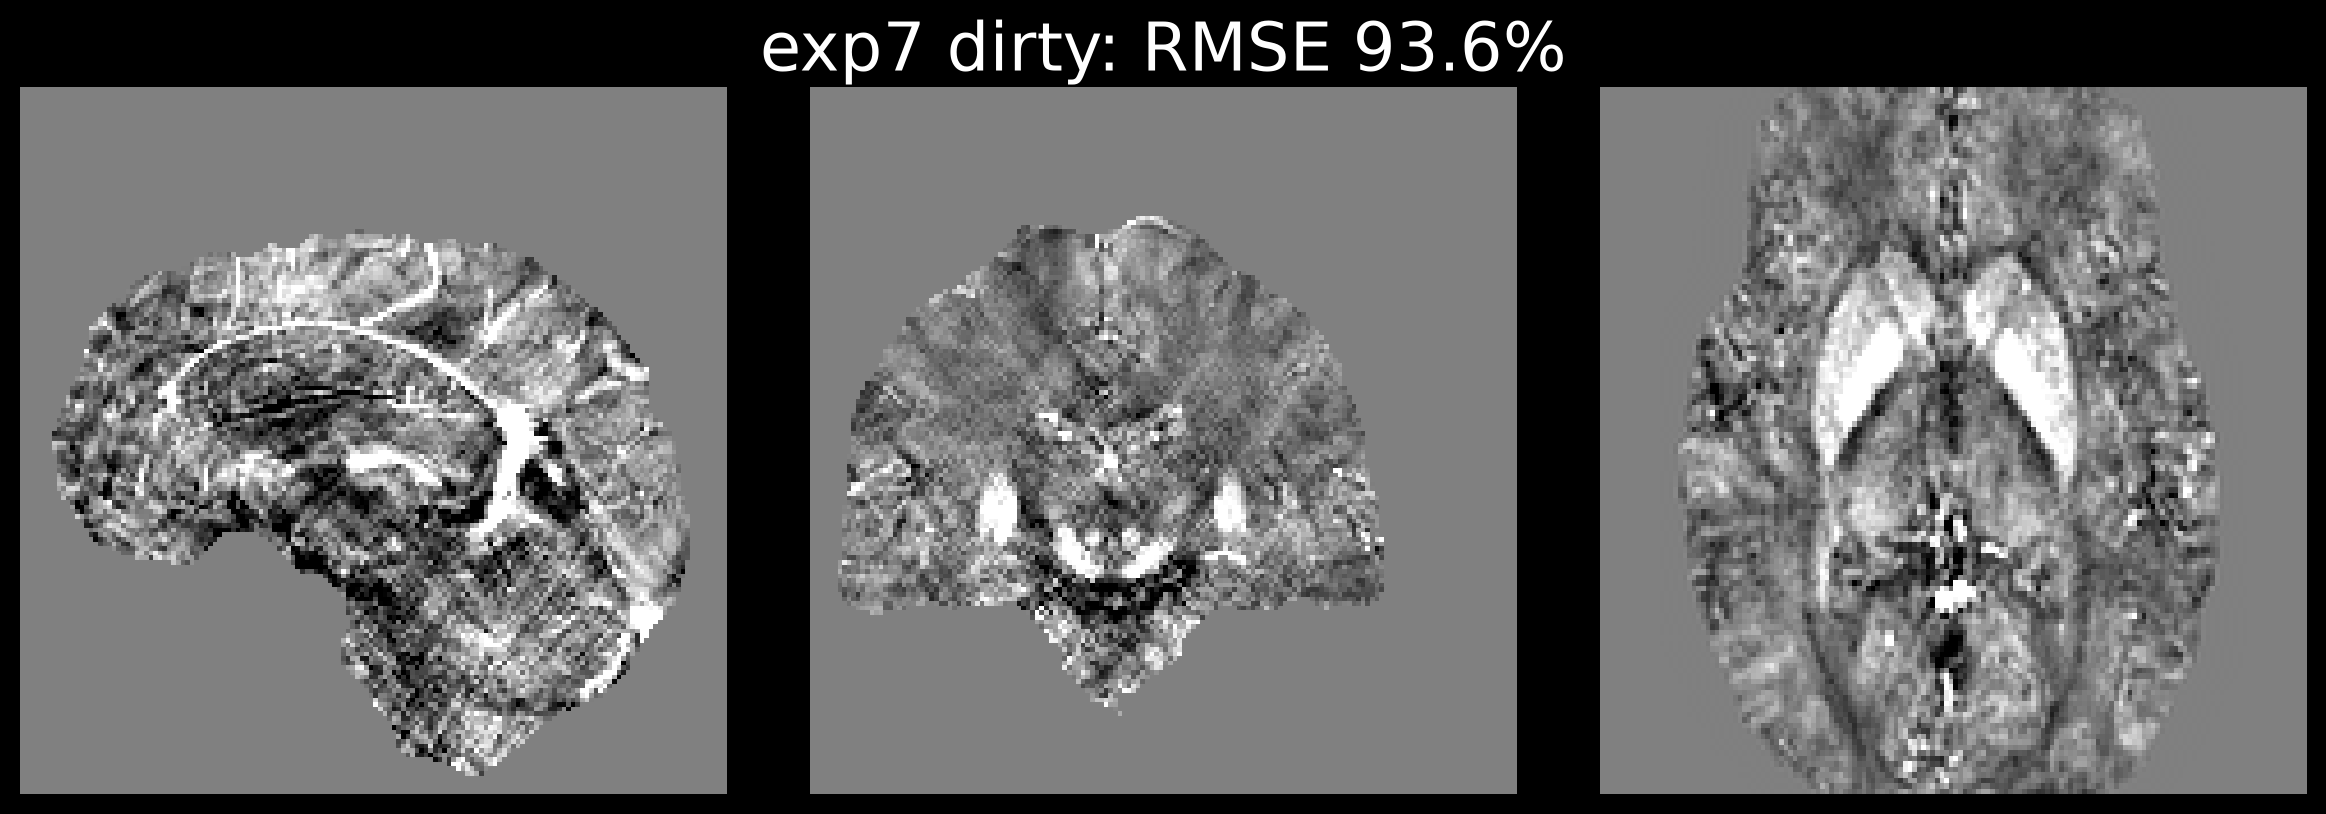

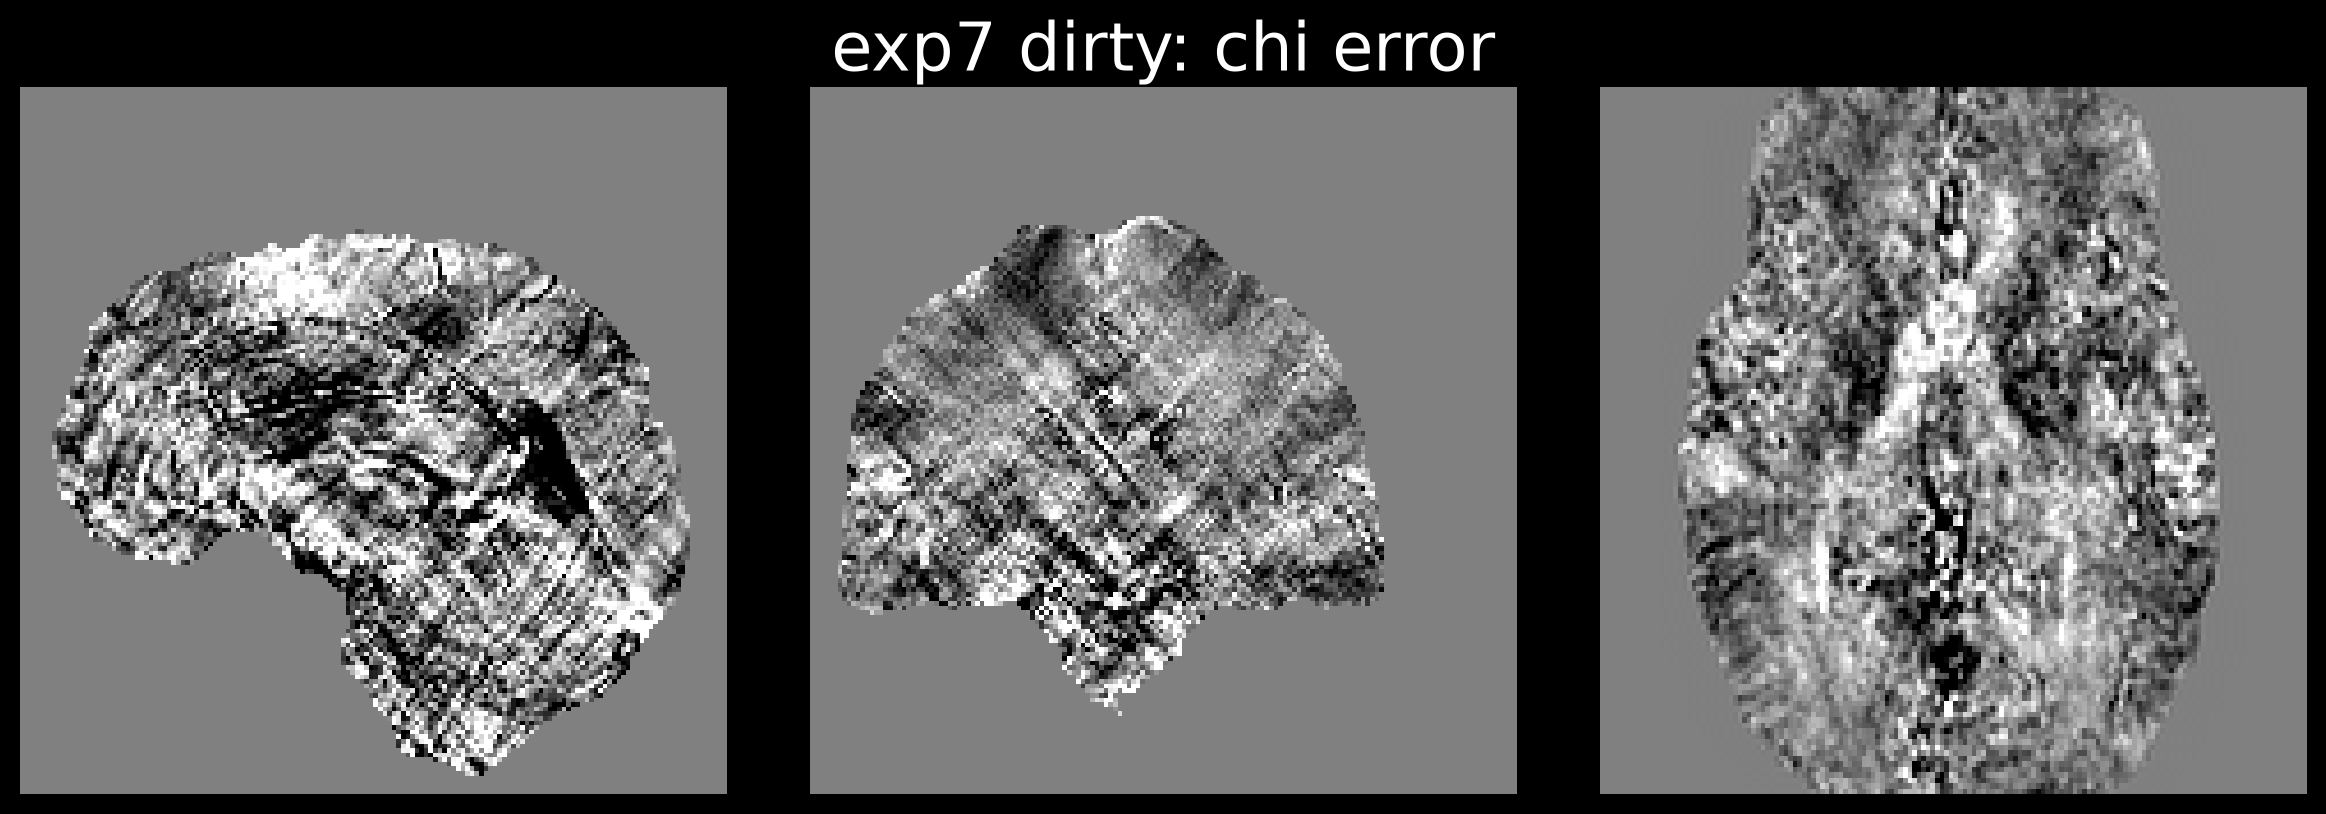

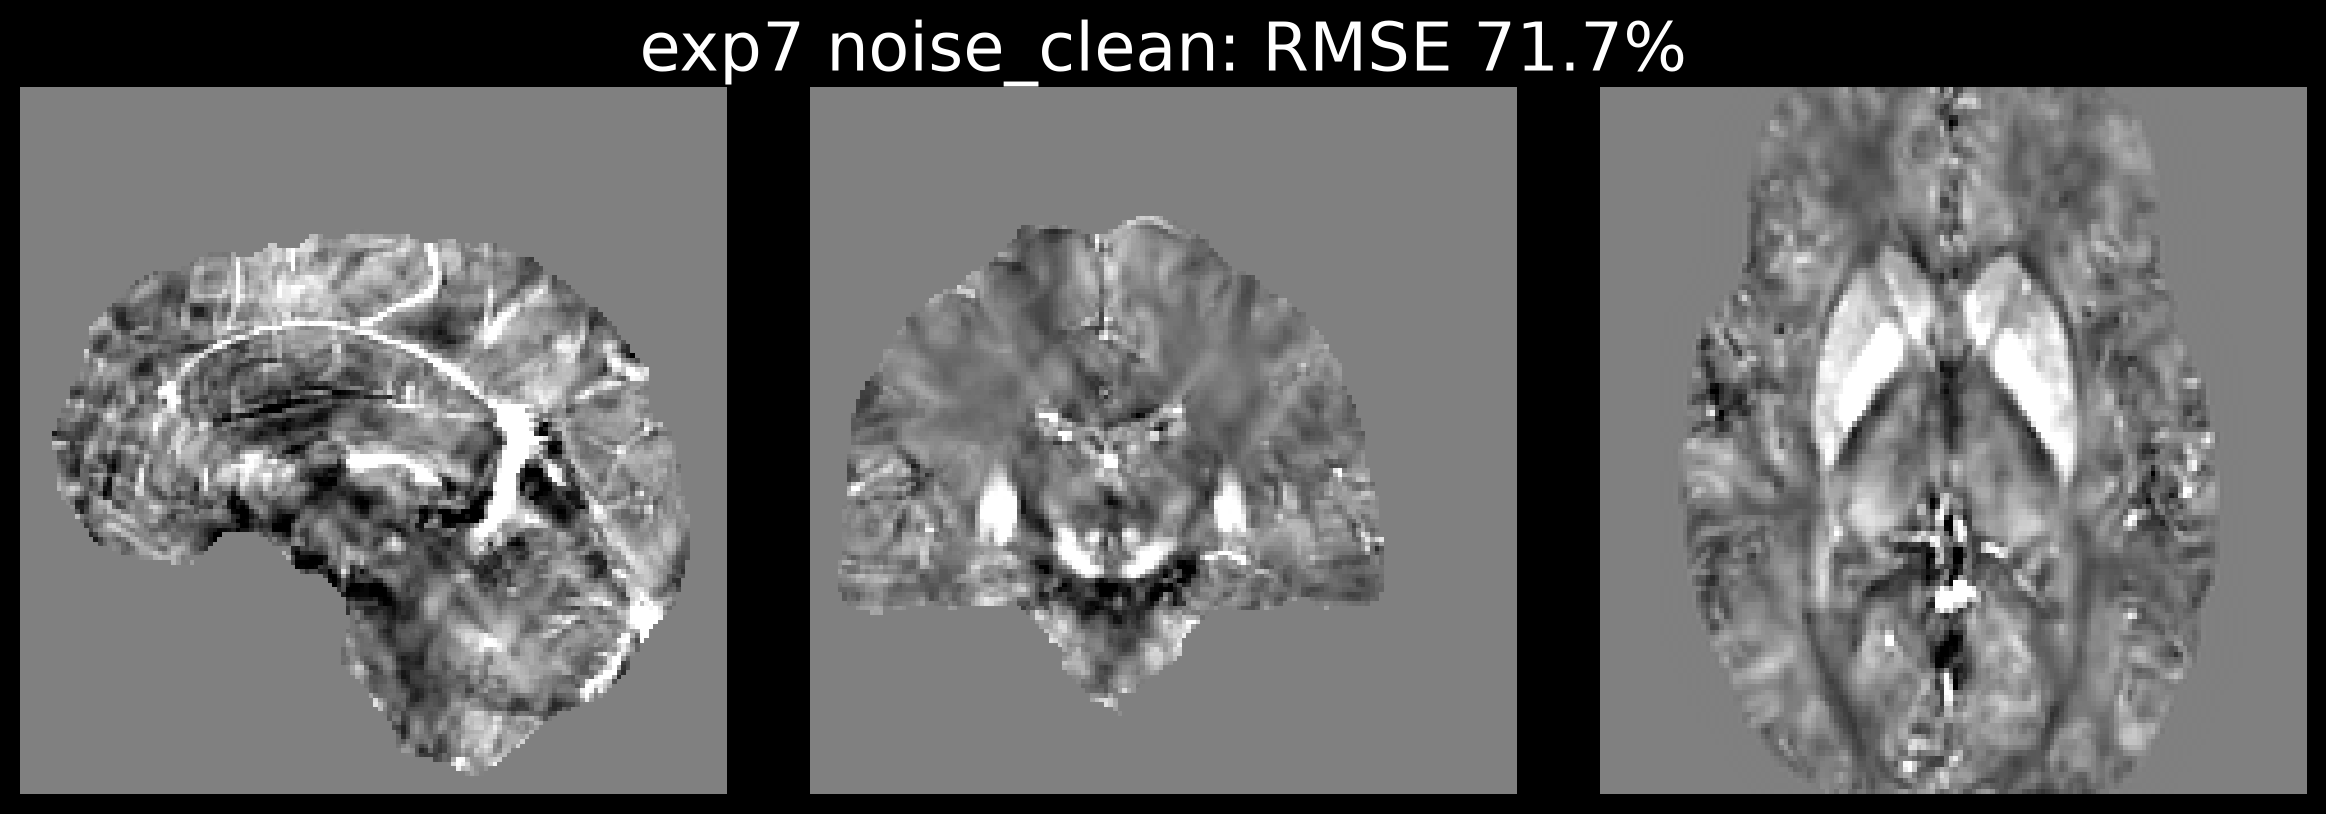

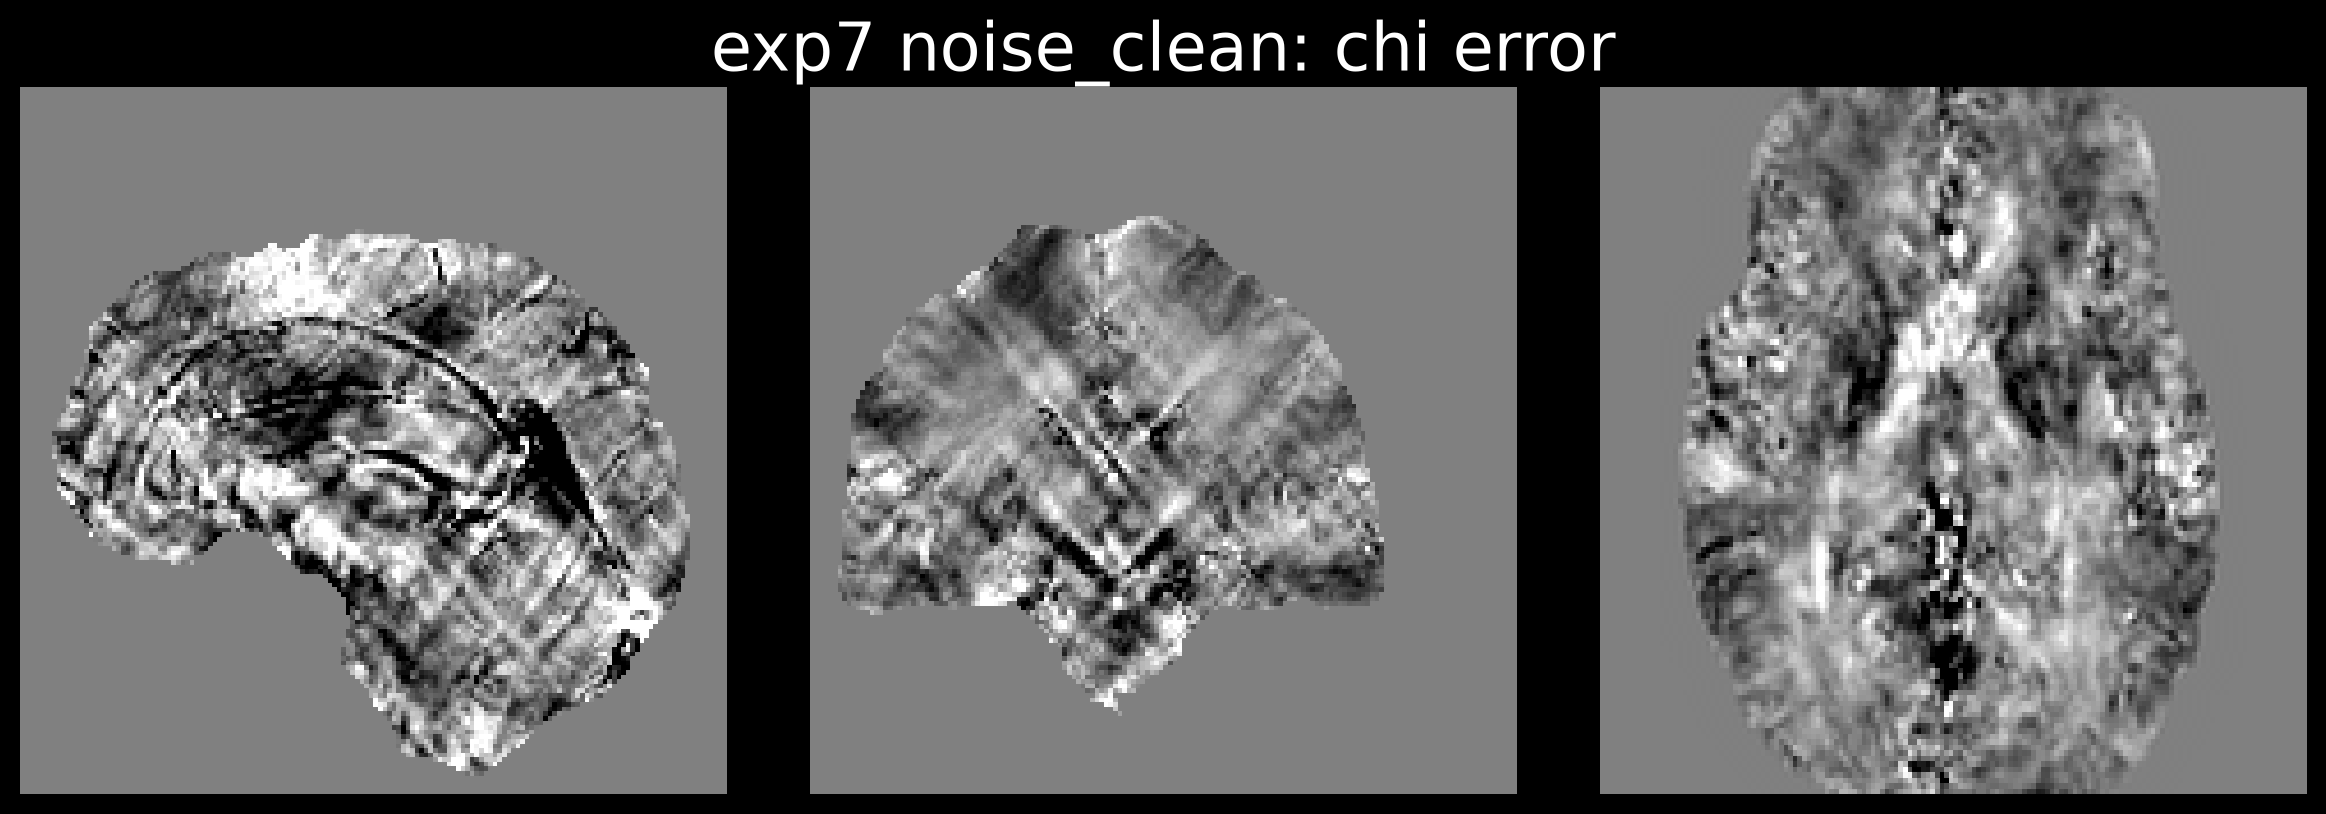

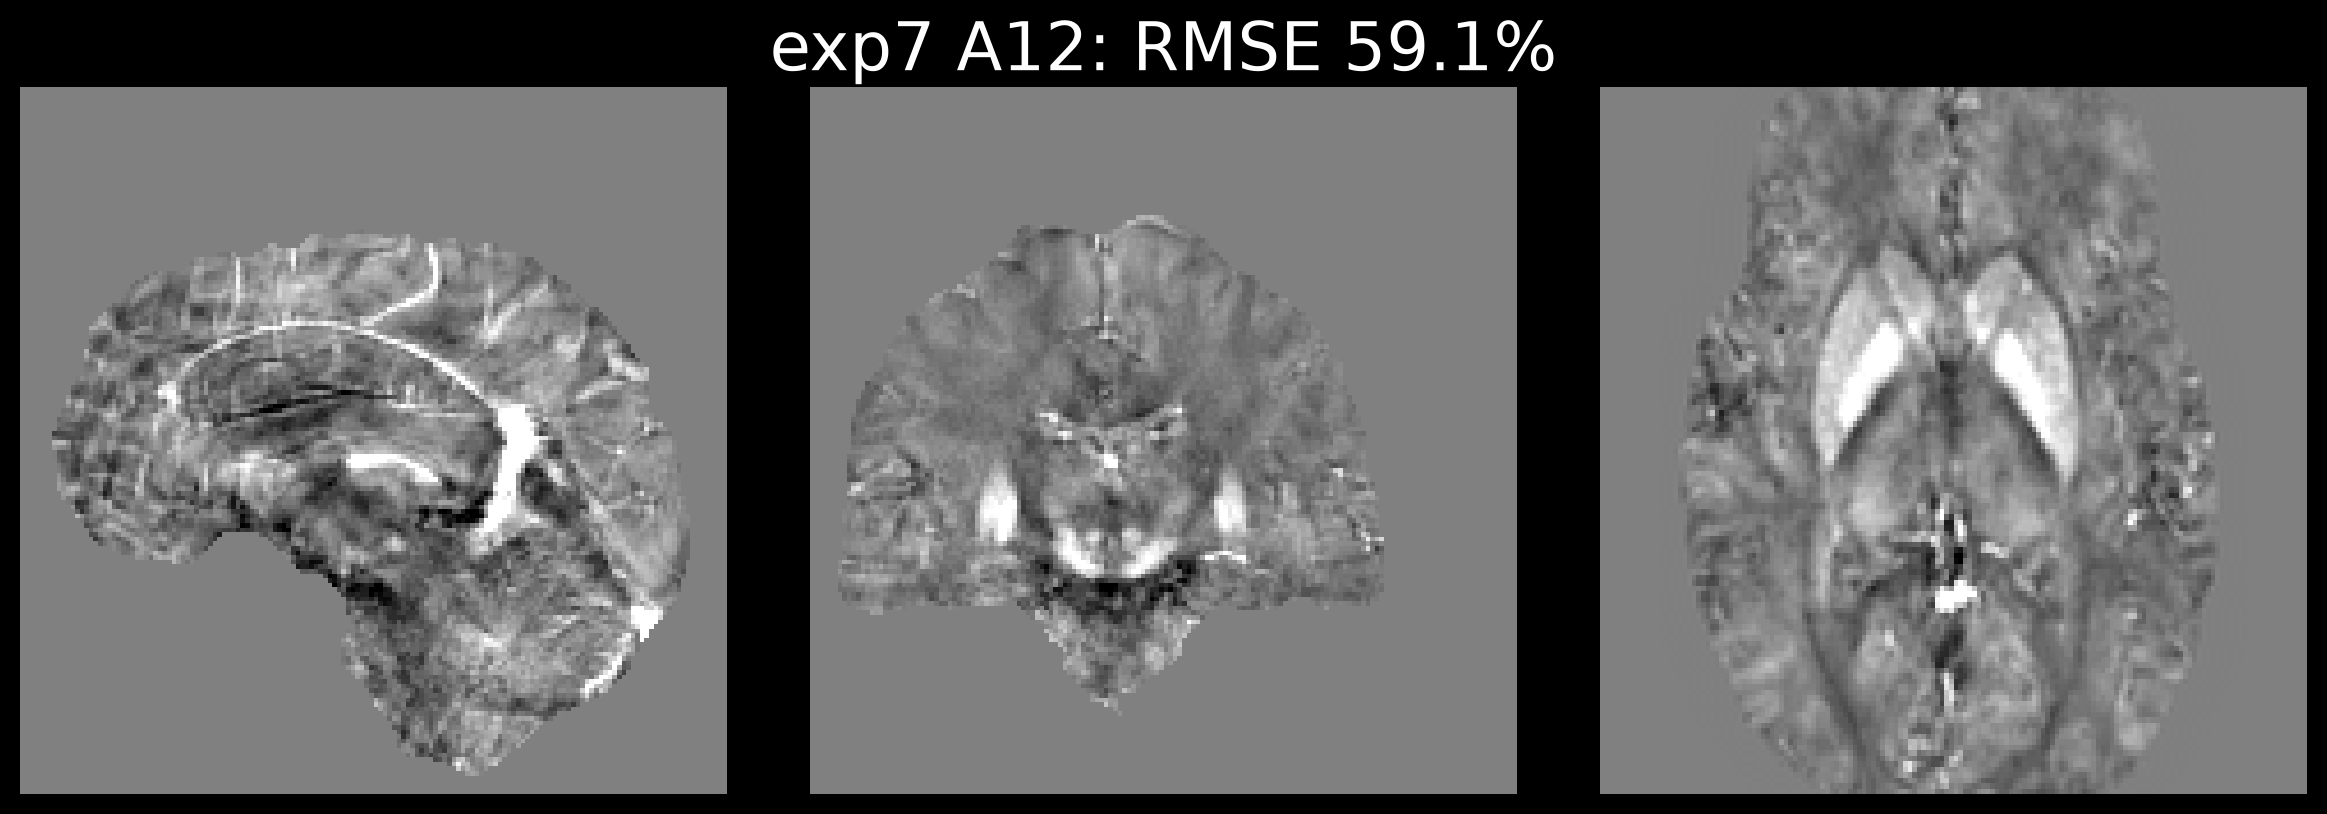

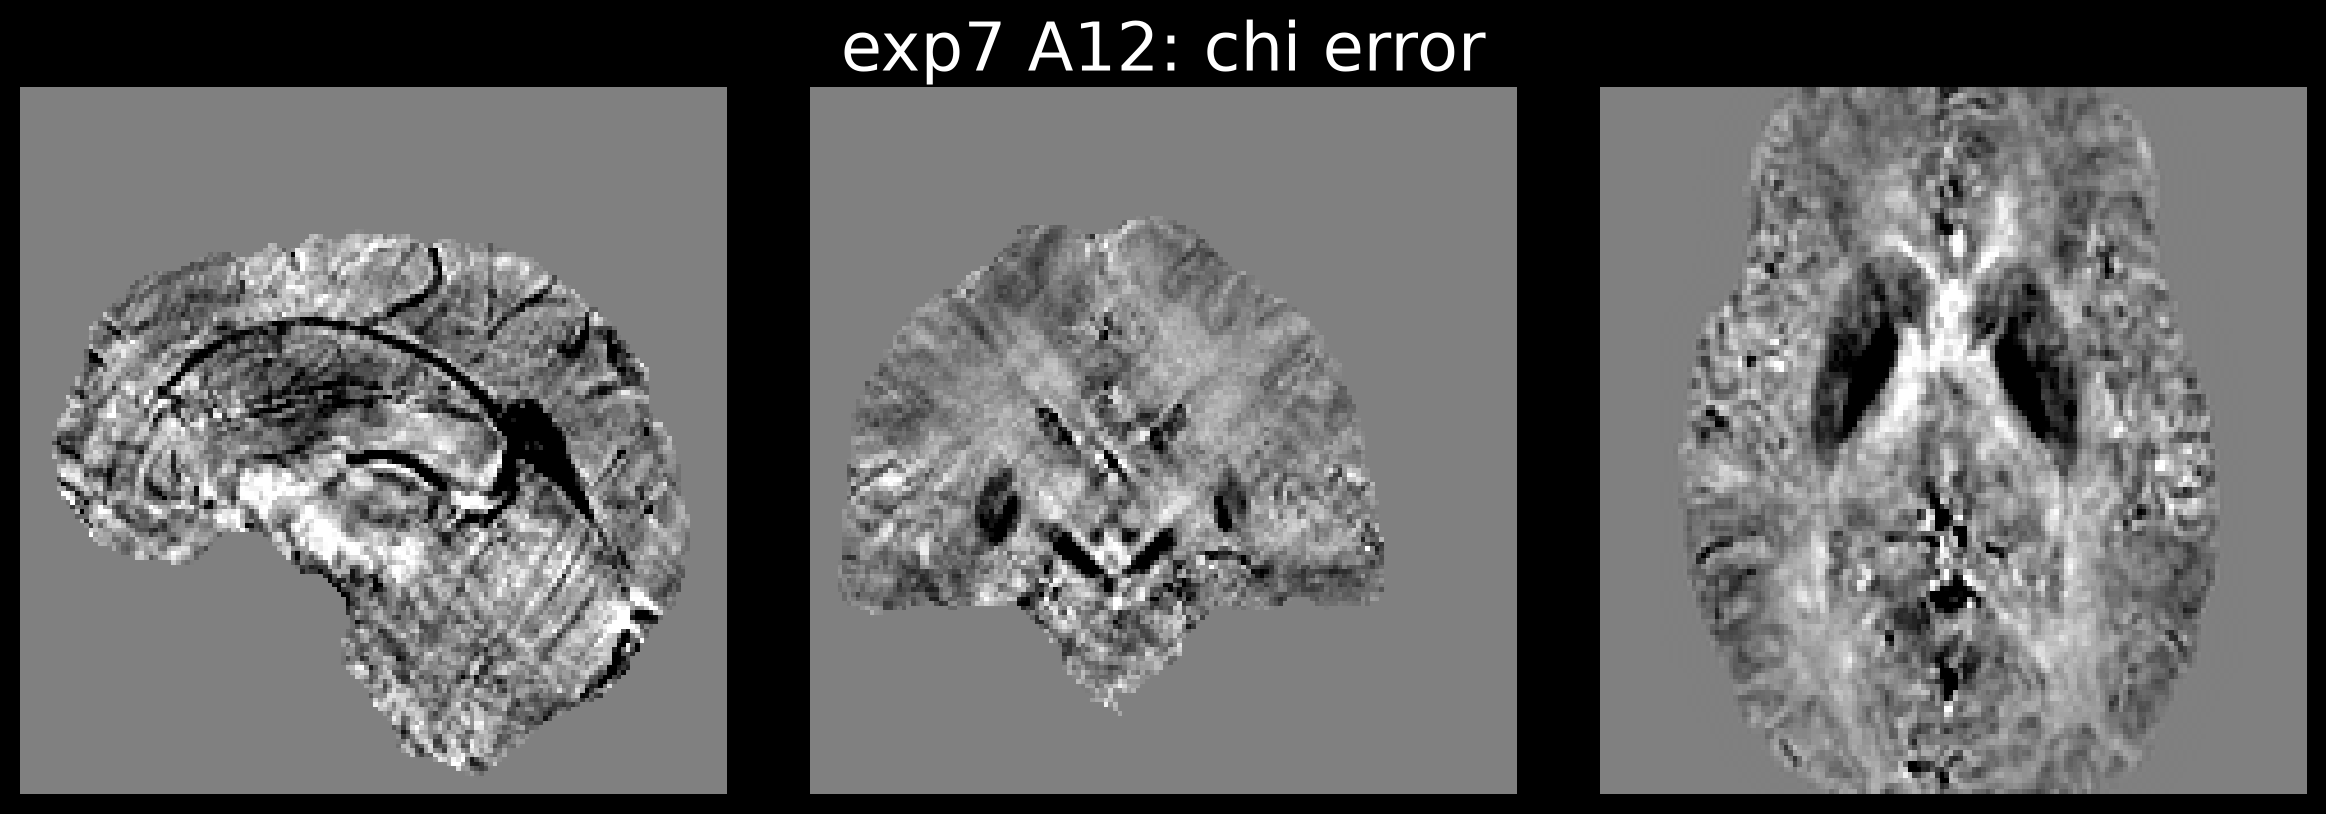

In [7]:
ROT = {"rc1": [90, 90, -90], "sim2": [90, 90, 90]}
def detail(exp, methods):
    gt, mk = gt_mask(exp)
    tag = "sim2" if exp.startswith("sim2") else "rc1"
    pos = tuple(n // 2 for n in gt.shape)
    imagesc3d2(gt * mk, pos, cmap="grey", contrast=CHI, fig_num=2, rot_deg=ROT[tag], scale_fig=[-0.12, 0.12, -0.12, 0.12], avg_size=0, title_fig=f"{exp}: ground truth"); show()
    for m in methods:
        x = chi_map(exp, m)
        if x is None:
            print("missing:", m); continue
        imagesc3d2(x * mk, pos, cmap="grey", contrast=CHI, fig_num=2, rot_deg=ROT[tag], scale_fig=[-0.12, 0.12, -0.12, 0.12], avg_size=0,
                   title_fig=f"{exp} {m}: RMSE {compute_rmse(x[mk], gt[mk]):.1f}%"); show()
        imagesc3d2((x - gt) * mk, pos, cmap="grey", contrast=CHI_ERR, fig_num=2, rot_deg=ROT[tag], scale_fig=[-0.12, 0.12, -0.12, 0.12], avg_size=0,
                   title_fig=f"{exp} {m}: chi error"); show()

detail("exp7", ["dirty", "noise_clean", "A12"])

### What the numbers and maps say about claim 1 (verdict is in the last section)

In [8]:
e7 = dict(zip([c[0] for c in COLS], rows["exp7"]))
e8 = dict(zip([c[0] for c in COLS], rows["exp8"]))
e9 = dict(zip([c[0] for c in COLS], rows["exp9"]))
s2 = dict(zip([c[0] for c in COLS], rows["sim2_real"]))
print("exp7 (measured residual, the clean test):")
print(f"  dirty {e7['dirty']:.2f} | A12 {e7['A12']:.2f} | A gated {e7['A']:.2f} | noise_clean {e7['noise_clean']:.2f} | realmix_plain {e7['realmix_plain']:.2f} | gain net GNa {GAIN['exp7'][0]:.2f} | regime {e7['regime']:.2f} | AB {e7['AB']:.2f} | GN {GAIN['exp7'][1]:.2f}")
beats = {k: e7['A12'] < e7[k] for k in ("noise_clean", "realmix_plain")}
print("  A12 beats noise_clean / realmix_plain / GNa:", beats["noise_clean"], beats["realmix_plain"], e7['A12'] < GAIN['exp7'][0])
print(f"  A12 minus regime (joint net): {e7['A12'] - e7['regime']:+.2f} points  (positive = the 12 numbers are WORSE)")
print("exp8 / exp9 (modelled residuals, in-family for the networks):")
print(f"  A12 {e8['A12']:.2f} / {e9['A12']:.2f}  vs noise_clean {e8['noise_clean']:.2f} / {e9['noise_clean']:.2f}, realmix_plain {e8['realmix_plain']:.2f} / {e9['realmix_plain']:.2f}, regime {e8['regime']:.2f} / {e9['regime']:.2f}")
print("Sim2 real (noise-like psi): A12 %.2f | dirty %.2f | noise_clean %.2f" % (s2['A12'], s2['dirty'], s2['noise_clean']))

exp7 (measured residual, the clean test):
  dirty 93.60 | A12 59.15 | A gated 61.37 | noise_clean 71.69 | realmix_plain 61.45 | gain net GNa 66.33 | regime 56.58 | AB 58.63 | GN 58.24
  A12 beats noise_clean / realmix_plain / GNa: True True True
  A12 minus regime (joint net): +2.56 points  (positive = the 12 numbers are WORSE)
exp8 / exp9 (modelled residuals, in-family for the networks):
  A12 53.00 / 56.20  vs noise_clean 61.15 / 76.33, realmix_plain 54.13 / 64.62, regime 50.40 / 53.60
Sim2 real (noise-like psi): A12 55.93 | dirty 53.94 | noise_clean 47.31


## Claim 2 — noise is radial (scale), real psi is angular (|D|)

RC1 only (the one head with a measured non-dipolar phase). Four residuals psi on top of the clean field `b = mask * D * chi_cosmos`: synthetic noise (SNR 60), the **measured** tissue residual, the modelled STI and the modelled off-diagonal residual. Built by `scripts/analyze_claim_separability.py`.

**(a) Local SNR** `10 log10(|B|^2 / |PSI|^2)` per cell of the (|k|, |D|) plane. If a residual is separable by scale, the colour changes along the vertical axis (|k|) and not along the horizontal (|D|); if by angle, the other way round.

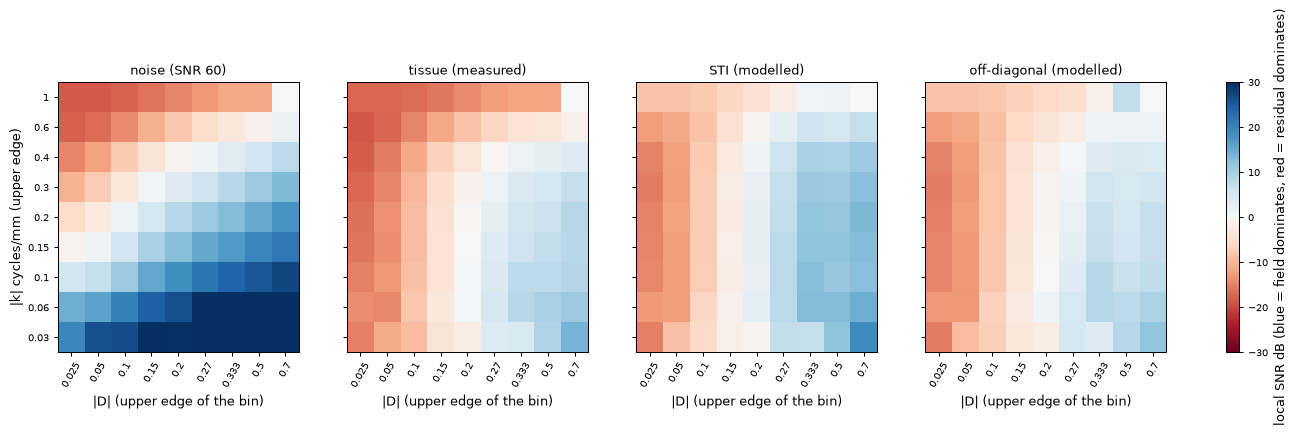

In [9]:
names = [str(n) for n in SEP["names"]]
KE, DE = SEP["KE"], SEP["DE"]
fig, ax = plt.subplots(1, 4, figsize=(17, 3.9), sharey=True)
for a, n in zip(ax, names):
    im = a.imshow(SEP[f"snr_db__{n}"], origin="lower", aspect="auto", cmap="RdBu", vmin=-30, vmax=30)
    a.set_xticks(range(len(DE) - 1), [f"{v:g}" for v in DE[1:]], rotation=60); a.set_xlabel("|D| (upper edge of the bin)")
    a.set_yticks(range(len(KE) - 1), [f"{v:g}" for v in KE[1:]]); a.set_title(n)
ax[0].set_ylabel("|k| cycles/mm (upper edge)")
fig.colorbar(im, ax=ax, label="local SNR dB (blue = field dominates, red = residual dominates)", fraction=0.015)
show()

**(b) The best scalar gain** (least squares, per cell, fitted on the volume itself, so it is an *oracle*: a statement about what exists in the data, not a trained result) as a function of |D| alone and of |k| alone. A filter that attenuates by *scale* has a gain that moves with |k| and is flat in |D|; one that attenuates by *angle* moves with |D|.

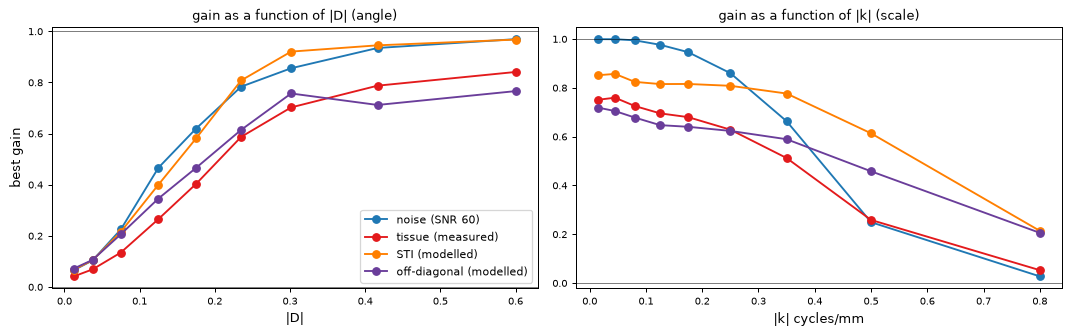

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
cols = {"noise (SNR 60)": "#1f78b4", "tissue (measured)": "#e31a1c", "STI (modelled)": "#ff7f00", "off-diagonal (modelled)": "#6a3d9a"}
xd = 0.5 * (DE[:-1] + DE[1:]); xk = 0.5 * (KE[:-1] + KE[1:])
for n in names:
    ax[0].plot(xd, np.clip(SEP[f"gain_angular__{n}"], -0.2, 1.2), "o-", color=cols[n], label=n)
    ax[1].plot(xk, np.clip(SEP[f"gain_radial__{n}"], -0.2, 1.2), "o-", color=cols[n], label=n)
ax[0].set_xlabel("|D|"); ax[0].set_ylabel("best gain"); ax[0].set_title("gain as a function of |D| (angle)")
ax[1].set_xlabel("|k| cycles/mm"); ax[1].set_title("gain as a function of |k| (scale)")
for a in ax:
    a.axhline(1, color="k", lw=0.4); a.axhline(0, color="k", lw=0.4)
ax[0].legend()
plt.tight_layout()
show()

**(c) What each geometry buys.** Phase NRMSE (%) of the dirty field after a linear filter whose gain may depend only on |k| (RADIAL), only on |D| (ANGULAR), or on both (CELL). The diagonal blocks of the matrices use gains fitted on the same residual; the off-diagonal ones apply gains fitted on another residual (the cost of using the wrong geometry).

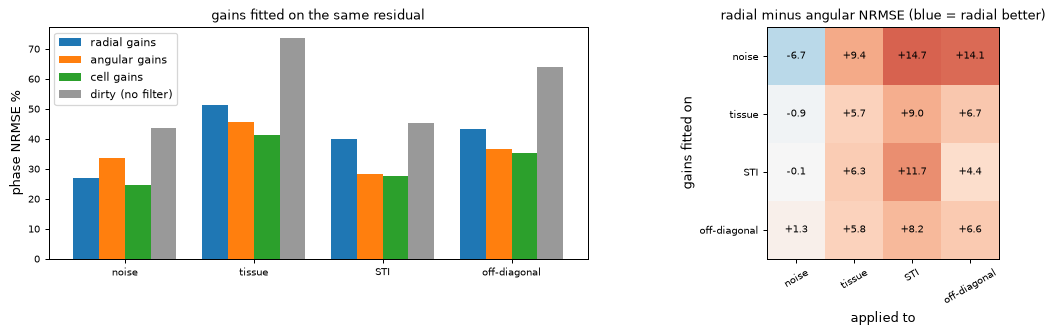

                                noise (SNR 60)   tissue (measured)      STI (modelled)  off-diagonal (mode
dirty                                    43.55               73.58               45.23               63.83
radial <- noise (SNR 6                   26.85               59.01               43.43               57.29
radial <- tissue (meas                   36.63               51.22               43.36               43.94
radial <- STI (modelle                   33.48               56.53               39.87               48.28
radial <- off-diagonal                   39.98               52.46               43.64               43.16
angular <- noise (SNR 6                  33.53               49.60               28.71               43.22
angular <- tissue (meas                  37.49               45.54               34.36               37.28
angular <- STI (modelle                  33.62               50.20               28.15               43.87
angular <- off-diagonal              

In [11]:
modes = ["radial", "angular", "cell"]
ident = [SEP[f"nrmse_identity__{n}"] for n in names]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
w = 0.2
for i, mode in enumerate(modes):
    own = [SEP[f"cross__{mode}"][j, j] for j in range(len(names))]
    ax[0].bar(np.arange(len(names)) + (i - 1) * w, own, w, label=f"{mode} gains")
ax[0].bar(np.arange(len(names)) + 2 * w, ident, w, color="#999999", label="dirty (no filter)")
ax[0].set_xticks(np.arange(len(names)) + w / 2, [n.split(" (")[0] for n in names]); ax[0].set_ylabel("phase NRMSE %"); ax[0].legend(); ax[0].set_title("gains fitted on the same residual")
cross = np.array([[SEP["cross__radial"][i, j] - SEP["cross__angular"][i, j] for j in range(len(names))] for i in range(len(names))])
im = ax[1].imshow(SEP["cross__radial"] - SEP["cross__angular"], cmap="RdBu_r", vmin=-25, vmax=25)
ax[1].set_xticks(range(len(names)), [n.split(" (")[0] for n in names], rotation=30); ax[1].set_yticks(range(len(names)), [n.split(" (")[0] for n in names])
ax[1].set_xlabel("applied to"); ax[1].set_ylabel("gains fitted on"); ax[1].set_title("radial minus angular NRMSE (blue = radial better)")
for i in range(len(names)):
    for j in range(len(names)):
        ax[1].text(j, i, f"{cross[i, j]:+.1f}", ha="center", va="center", fontsize=8)
plt.tight_layout()
show()
print(f"{'':26s}" + "".join(f"{n[:18]:>20s}" for n in names))
print(f"{'dirty':26s}" + "".join(f"{v:20.2f}" for v in ident))
for mode in modes:
    for i, fit in enumerate(names):
        print(f"{mode + ' <- ' + fit[:12]:26s}" + "".join(f"{SEP[f'cross__{mode}'][i, j]:20.2f}" for j in range(len(names))))

**(d) The same statement through the inversion (no training, no filter fitting).** Oracle replacement tests of `scripts/gate_suite.py`: replace the true field in a region of Fourier space and see how much of the dirty-to-oracle eNDI gap closes (25 fixed iterations). Noise-like Sim2 (psi radial): replacing |D| < 0.1 does not help (it makes it worse), replacing |k| >= 0.2 closes a large part. Real RC1 residuals (psi angular): replacing |D| < 0.2 closes 62-81%.

In [12]:
t = find("runs/gates/table.txt", required=False)
if t:
    text = t.read_text().splitlines()
    keep = ("[sim2]", "[rc1_exp7]", "[rc1_exp8]", "[rc1_exp9]", "start = dirty", "fix |D|<0.1 ", "fix |D|<0.2", "fix |D|>=0.1", "fix |k|>=0.2", "fix |k|<0.2", "notch0.1 ", "notch0.15")
    block, show_rows = None, False
    for ln in text:
        if ln.startswith("["):
            block = ln; print(ln)
        elif ln.strip().startswith("start ="):
            start = ln.strip(); print("  " + start)
            show_rows = "dirty" in start
        elif show_rows and ln.strip().startswith(("fix |D|<0.1", "fix |D|<0.2", "fix |D|>=0.1", "fix |k|<0.2", "fix |k|>=0.2", "notch0.1 ", "notch0.15")):
            print("    " + ln.strip())
else:
    print("runs/gates/table.txt not found")

[sim2] oracle 43.10
  start = dirty: 53.94
    fix |D|<0.1        57.33   closure  -31.2%
    fix |D|<0.2        51.92   closure   18.6%
    fix |D|>=0.1       47.92   closure   55.5%
    fix |k|<0.2        54.57   closure   -5.8%
    fix |k|>=0.2       47.76   closure   57.1%
    notch0.1           59.77   closure  -53.7%
    notch0.15          61.80   closure  -72.5%
  start = noise_clean: 47.31
[rc1_exp7] oracle 35.76
  start = dirty: 93.60
    fix |D|<0.1        76.46   closure   29.6%
    fix |D|<0.2        57.42   closure   62.6%
    fix |D|>=0.1       73.72   closure   34.4%
    fix |k|<0.2        72.65   closure   36.2%
    fix |k|>=0.2       69.82   closure   41.1%
    notch0.1           70.45   closure   40.0%
    notch0.15          64.83   closure   49.7%
[rc1_exp8] oracle 35.76
  start = dirty: 67.69
    fix |D|<0.1        52.06   closure   49.0%
    fix |D|<0.2        41.75   closure   81.3%
    fix |D|>=0.1       48.48   closure   60.2%
    fix |k|<0.2        46.43   clos

## Headroom test — TV on chi (`fansiTV`, magnitude weighting)

**What is run** (server, `scripts/export_claim_views.py`, no training): for the inputs `dirty`, `B` (noise_clean), `A12`, `AB` and `oracle` (clean masked field), on `exp7`, `exp8`, `exp9` and the real Sim2, a `fansiTV` inversion (linear, data weight = the eNDI magnitude weight, `mu1 = 100 alpha`, `mu2 = 1`, 150 ADMM iterations, padded as the eNDI scoring) for alpha in {5e-5, 1e-4, 2e-4, 3e-4, 5e-4}. alpha is chosen **separately for RC1 and Sim2** (their data scales differ) with the **ground truth**, so these numbers are oracle-tuned and optimistic; Sim2 is tuned on its own truth, which is allowed for a diagnostic and not for a design input.

**Criteria fixed before the result:**
1. Real Sim2: TV of `B` at its best alpha is at least 1.0 below the best eNDI iteration of `B` (46.42, minimum over 40 iterations; 47.48 at the 25-iteration standard) -> TV of B <= 45.4.
2. `exp7` (measured residual): TV of `A12` at its best alpha is at least 3.0 below the AB eNDI value (58.63) -> TV of A12 <= 55.6.
3. Reading: 1 and 2 met -> the chi prior adds information beyond the field-domain stage; the next step is a chi-bottleneck network (C3 of 9ap). Only 1 -> it helps the noise regime only. Neither -> no headroom, the field-domain line is closed. A gain that appears with `oracle` input but not with cleaned input means the TV inverter is simply better regularised than 25 eNDI iterations, not that a cleaner is needed.

In [13]:
if S is None or not M_SRV or not any(k.startswith("tv/") for k in M_SRV):
    print("TV sweep not yet available: run on the server\n  MCNO_VRAM_GB=10 nohup .venv/bin/python scripts/export_claim_views.py > runs/claim_views.log 2>&1 &\n"
          "then copy runs/claim_views/ here (see the commands in the chat).")
    TV = False
else:
    TV = True
    ALPHAS = sorted({float(k.split("/")[-1]) for k in M_SRV if k.startswith("tv/")})
    SET_NAMES = ["exp7", "exp8", "exp9", "sim2_real"]
    INPUTS = ["dirty", "B", "A12", "AB", "oracle"]
    print("TV NRMSE % (final ADMM iteration) per alpha, with the eNDI 25-iteration and eNDI-minimum values of the same input")
    print(f"{'set':10s}{'input':8s}" + "".join(f"{a:>9.0e}" for a in ALPHAS) + f"{'best':>9s}{'alpha*':>9s}{'eNDI@25':>9s}{'eNDI min':>9s}")
    best = {}
    for e in SET_NAMES:
        for i in INPUTS:
            vals = [M_SRV.get(f"tv/{e}/{i}/{a:g}", {}).get("nrmse", [np.nan])[-1] for a in ALPHAS]
            if all(np.isnan(vals)):
                continue
            k = int(np.nanargmin(vals)); best[(e, i)] = (vals[k], ALPHAS[k])
            h = M_SRV.get(f"endi/{e}/{i}", {}).get("nrmse")
            e25 = at({"nrmse": h}) if h else np.nan
            print(f"{e:10s}{i:8s}" + "".join(f"{v:9.2f}" for v in vals) + f"{vals[k]:9.2f}{ALPHAS[k]:9.0e}{e25:9.2f}{(min(h) if h else np.nan):9.2f}")

TV NRMSE % (final ADMM iteration) per alpha, with the eNDI 25-iteration and eNDI-minimum values of the same input
set       input       5e-05    1e-04    2e-04    3e-04    5e-04     best   alpha*  eNDI@25 eNDI min
exp7      dirty      110.23    93.59    79.26    72.38    66.25    66.25    5e-04    93.60    67.42
exp7      B           85.48    77.49    70.18    66.67    63.78    63.78    5e-04    71.69    61.62
exp7      A12         59.93    58.20    57.91    58.71    60.84    57.91    2e-04    59.15    58.86
exp7      AB          60.92    58.68    57.79    58.19    59.86    57.79    2e-04    58.63    58.12
exp7      oracle      22.57    25.94    31.34    35.54    41.77    22.57    5e-05    35.76    35.76
exp8      dirty       80.54    69.36    60.76    57.53    55.94    55.94    5e-04    67.69    53.83
exp8      B           73.52    65.71    59.40    57.04    56.08    56.08    5e-04    61.15    53.14
exp8      A12         51.83    51.83    53.52    55.40    58.69    51.83    1e-04    5

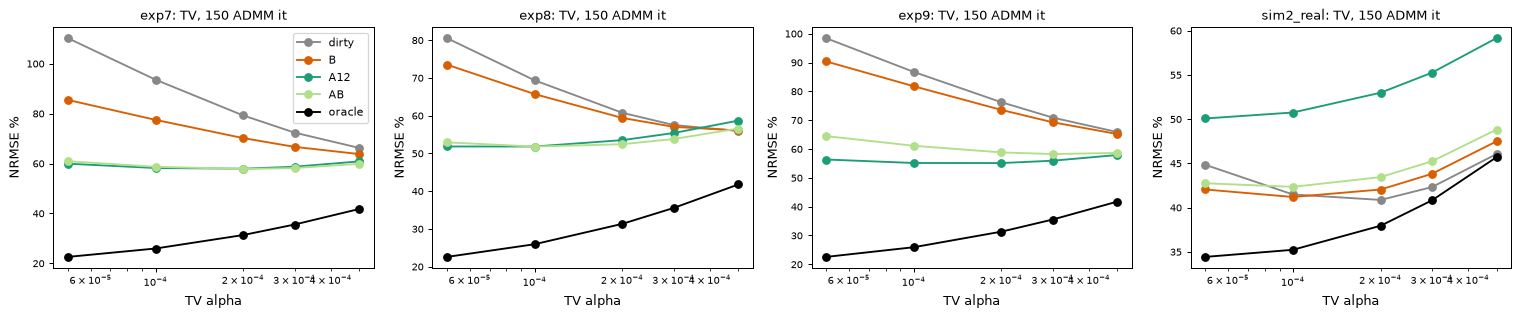

best alpha per set (input dirty): {'exp7': 0.0005, 'exp8': 0.0005, 'exp9': 0.0005, 'sim2_real': 0.0002}


In [14]:
if TV:
    fig, ax = plt.subplots(1, 4, figsize=(17, 3.6), sharey=False)
    for a, e in zip(ax, SET_NAMES):
        for i, c in zip(INPUTS, ["#888888", "#d95f02", "#1b9e77", "#b2df8a", "#000000"]):
            v = [M_SRV.get(f"tv/{e}/{i}/{al:g}", {}).get("nrmse", [np.nan])[-1] for al in ALPHAS]
            a.plot(ALPHAS, v, "o-", color=c, label=i)
        a.set_xscale("log"); a.set_xlabel("TV alpha"); a.set_ylabel("NRMSE %"); a.set_title(e + ": TV, 150 ADMM it")
    ax[0].legend()
    plt.tight_layout(); show()
    print("best alpha per set (input dirty):", {e: best.get((e, 'dirty'), (None, None))[1] for e in SET_NAMES})

In [15]:
if TV:
    ref_b = min(M_REG["sim2/sim2_real/noise_clean"]["nrmse"]) if "sim2/sim2_real/noise_clean" in M_REG else 46.42
    c1 = best[("sim2_real", "B")][0]
    c2 = best[("exp7", "A12")][0]
    ab = at(M_CASC["rc1/exp7/AB"])
    print(f"criterion 1: real Sim2 TV(B) = {c1:.2f}  needs <= {ref_b - 1.0:.2f}  (best eNDI iteration of B {ref_b:.2f}) -> {'MET' if c1 <= ref_b - 1.0 else 'NOT MET'}")
    print(f"criterion 2: exp7 TV(A12) = {c2:.2f}  needs <= {ab - 3.0:.2f}  (AB eNDI@25 {ab:.2f}) -> {'MET' if c2 <= ab - 3.0 else 'NOT MET'}")
    print("oracle input (ceiling for a TV inverter on the masked field): Sim2 %.2f, exp7 %.2f" % (best[("sim2_real", "oracle")][0], best[("exp7", "oracle")][0]))
    print("cleaner still helps under TV? dirty -> B on Sim2: %.2f -> %.2f ; dirty -> A12 on exp7: %.2f -> %.2f" % (
        best[("sim2_real", "dirty")][0], best[("sim2_real", "B")][0], best[("exp7", "dirty")][0], best[("exp7", "A12")][0]))

criterion 1: real Sim2 TV(B) = 41.20  needs <= 45.44  (best eNDI iteration of B 46.44) -> MET
criterion 2: exp7 TV(A12) = 57.91  needs <= 55.63  (AB eNDI@25 58.63) -> NOT MET
oracle input (ceiling for a TV inverter on the masked field): Sim2 34.42, exp7 22.57
cleaner still helps under TV? dirty -> B on Sim2: 40.86 -> 41.20 ; dirty -> A12 on exp7: 66.25 -> 57.91


In [16]:
if TV:
    print("XSIM (higher is better): TV at its best alpha vs eNDI at 25 iterations")
    for tag, e in (("sim2", "sim2_real"), ("rc1", "exp7")):
        e_x = {m: M_CASC[f"{tag}/{e}/{m}"]["xsim"][min(25, len(M_CASC[f"{tag}/{e}/{m}"]["xsim"]) - 1)] for m in ("dirty", "B", "AB")}
        t_x = {i: M_SRV[f"tv/{e}/{i}/{M_SRV['tv_best/%s/%s' % (e, i)]['alpha']:g}"]["xsim"][-1] for i in ("dirty", "B", "A12", "AB", "oracle")}
        print(f"  {e}: eNDI " + " | ".join(f"{k} {v:.3f}" for k, v in e_x.items()) + "    TV " + " | ".join(f"{k} {v:.3f}" for k, v in t_x.items()))

XSIM (higher is better): TV at its best alpha vs eNDI at 25 iterations
  sim2_real: eNDI dirty 0.489 | B 0.550 | AB 0.542    TV dirty 0.626 | B 0.626 | A12 0.529 | AB 0.619 | oracle 0.674
  exp7: eNDI dirty 0.240 | B 0.305 | AB 0.351    TV dirty 0.300 | B 0.292 | A12 0.319 | AB 0.317 | oracle 0.765


### TV susceptibility maps (best alpha per set and input)

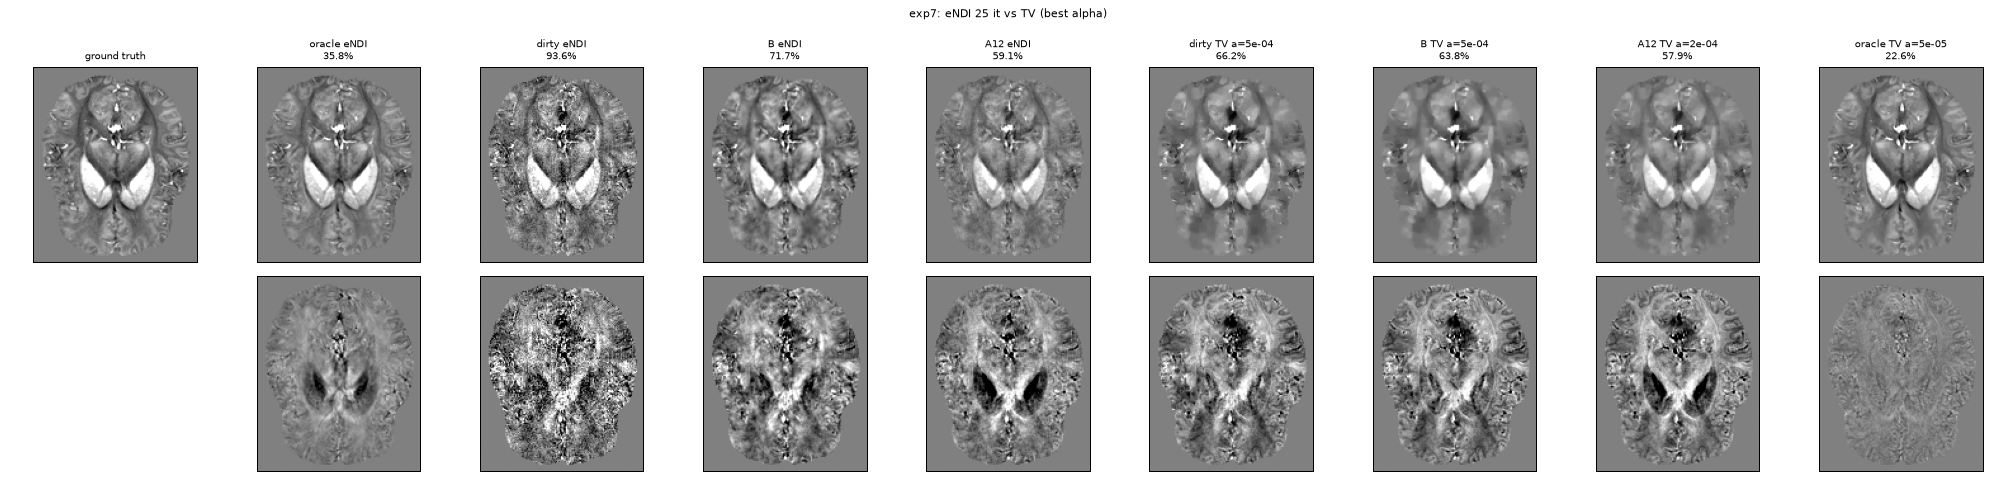

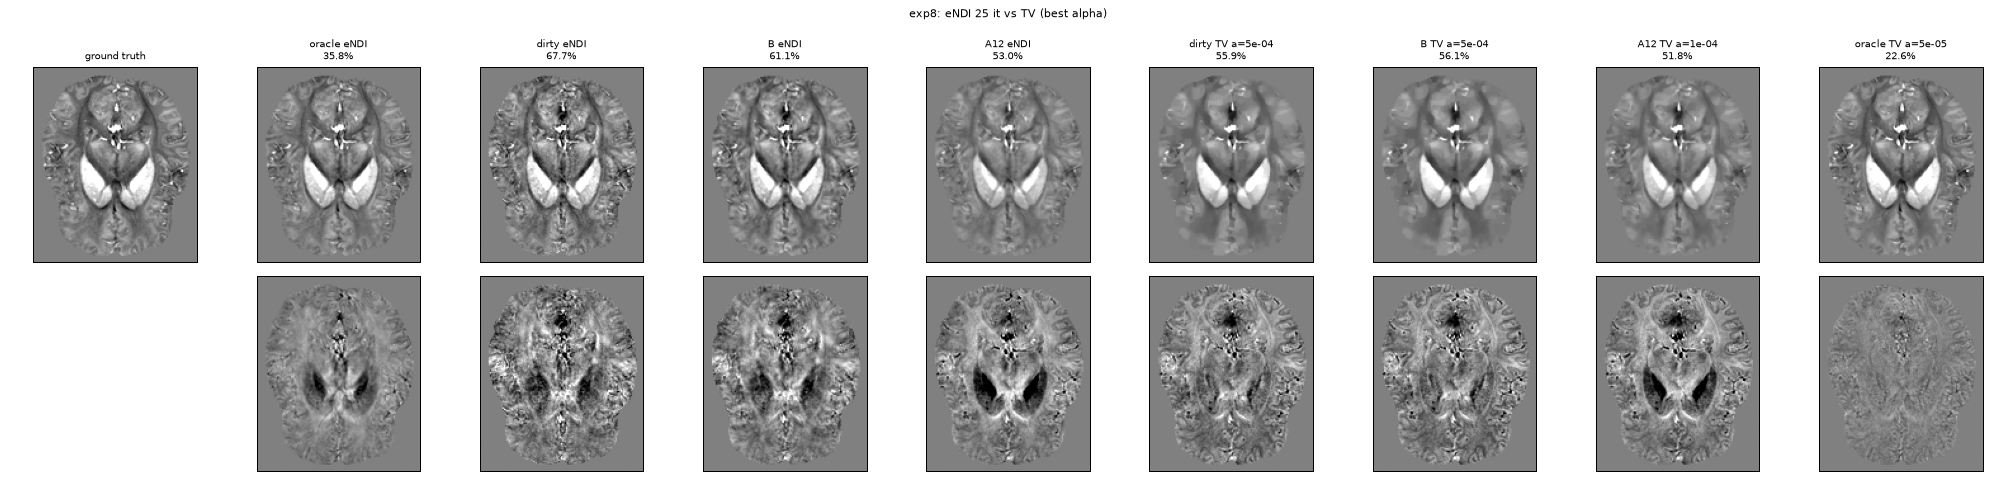

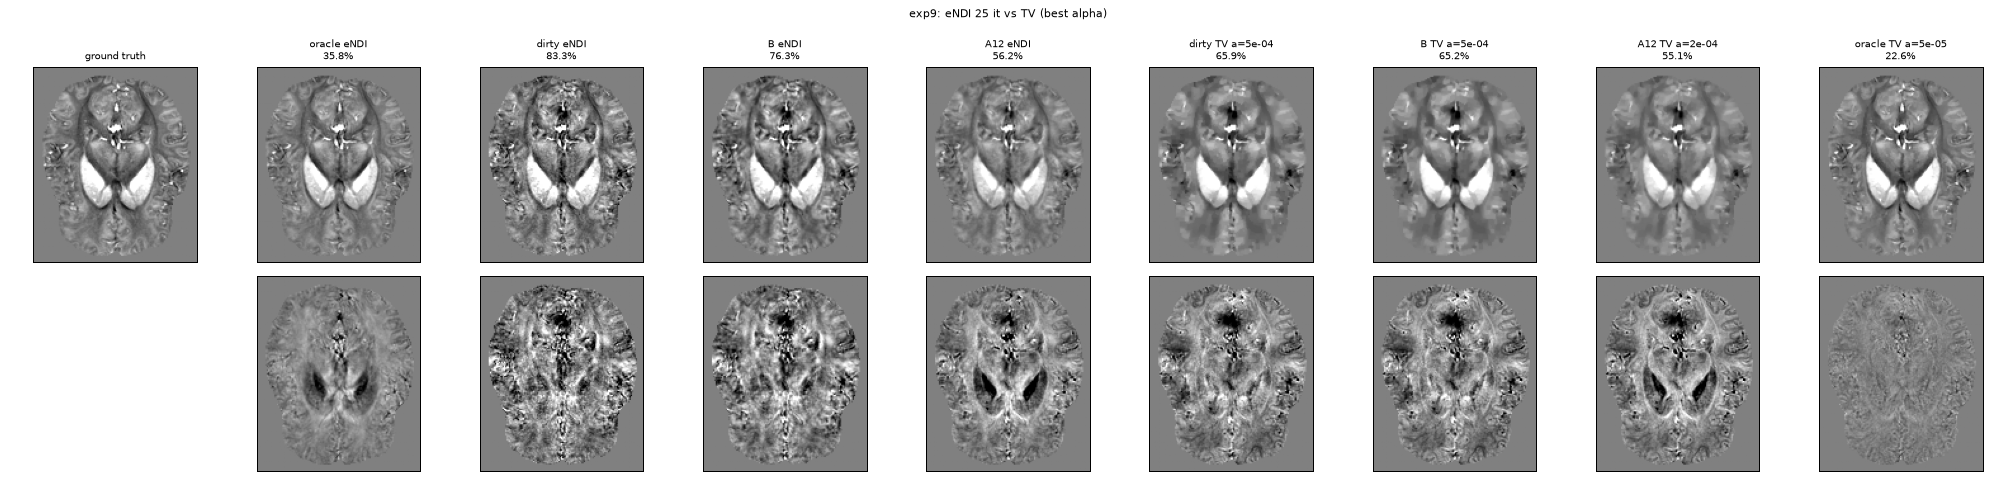

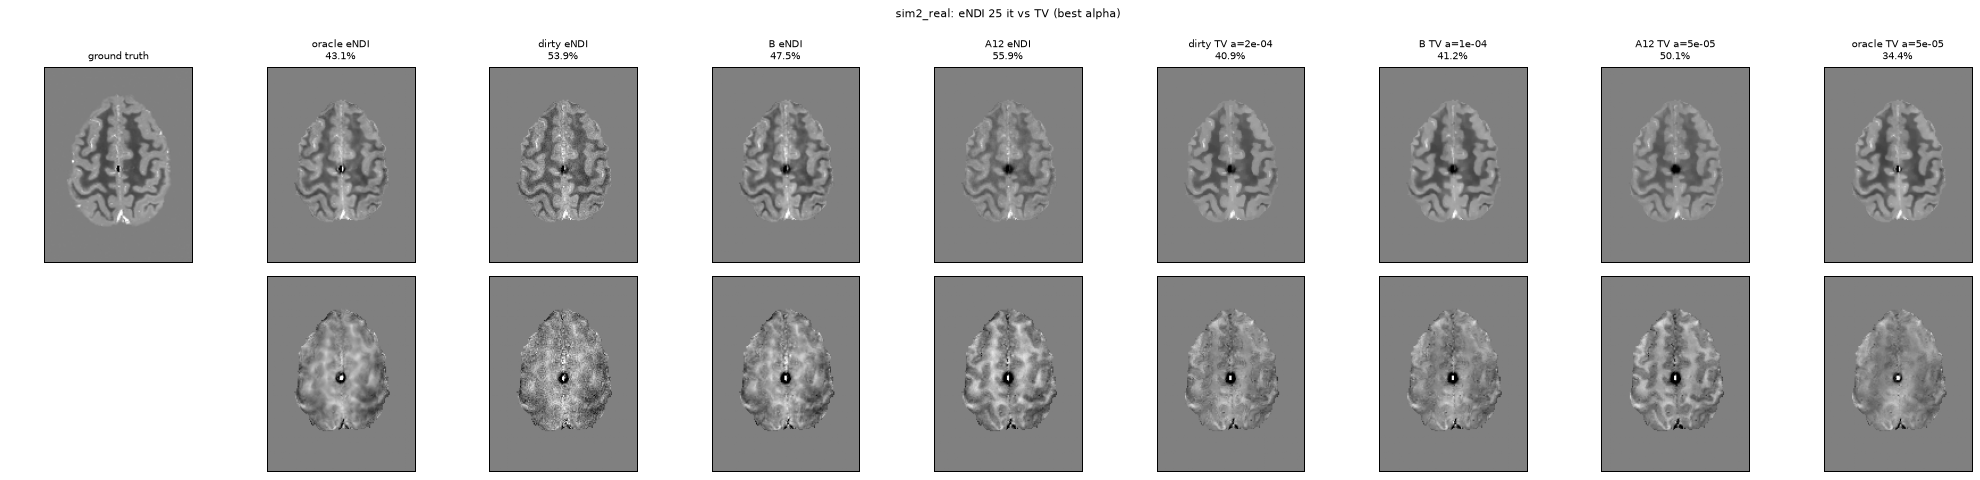

In [17]:
if TV:
    TVM = [("oracle", "oracle (eNDI)"), ("dirty", "dirty eNDI"), ("B", "B eNDI"), ("A12", "A12 eNDI")]
    for e in SET_NAMES:
        gt, mk = gt_mask(e)
        z = slice_of(e, gt)
        items = []
        for m, lab in [("endi_oracle", "oracle eNDI"), ("endi_dirty", "dirty eNDI"), ("endi_B", "B eNDI"), ("endi_A12", "A12 eNDI"),
                       ("tv_dirty", "dirty TV"), ("tv_B", "B TV"), ("tv_A12", "A12 TV"), ("tv_oracle", "oracle TV")]:
            for Z in (S, L):
                if Z is not None and f"{e}__chi_{m}" in Z.files:
                    items.append((lab + (f" a={best[(e, m.split('_')[1])][1]:.0e}" if m.startswith("tv_") else ""), Z[f"{e}__chi_{m}"].astype(np.float32))); break
        fig, ax = plt.subplots(2, len(items) + 1, figsize=(2.5 * (len(items) + 1), 5.4))
        ax[0, 0].imshow(np.rot90(gt[:, :, z]), cmap="gray", vmin=CHI[0], vmax=CHI[1]); ax[0, 0].set_title("ground truth", fontsize=8); ax[1, 0].axis("off")
        for i, (lab, x) in enumerate(items, 1):
            ax[0, i].imshow(np.rot90(x[:, :, z] * mk[:, :, z]), cmap="gray", vmin=CHI[0], vmax=CHI[1]); ax[0, i].set_title(f"{lab}\n{compute_rmse(x[mk], gt[mk]):.1f}%", fontsize=8)
            ax[1, i].imshow(np.rot90((x - gt)[:, :, z] * mk[:, :, z]), cmap="gray", vmin=CHI_ERR[0], vmax=CHI_ERR[1])
        for a in ax.ravel():
            a.set_xticks([]); a.set_yticks([])
        fig.suptitle(f"{e}: eNDI 25 it vs TV (best alpha)", fontsize=9); plt.tight_layout(); show()

## Real Sim2 in sagittal and coronal planes

Planes through the strongest source (the calcification, the dark/bright dot in the ground truth). Sagittal = fixed x (the image shows y horizontally and z vertically, z up); coronal = fixed y (x horizontal, z up). Same grey scale as above (+-0.1 ppm, error +-0.05 ppm). Change `PLANES` / `OFFSET` in the cell to move the plane (indices in the cropped box; `OFFSET` shifts the plane in voxels).

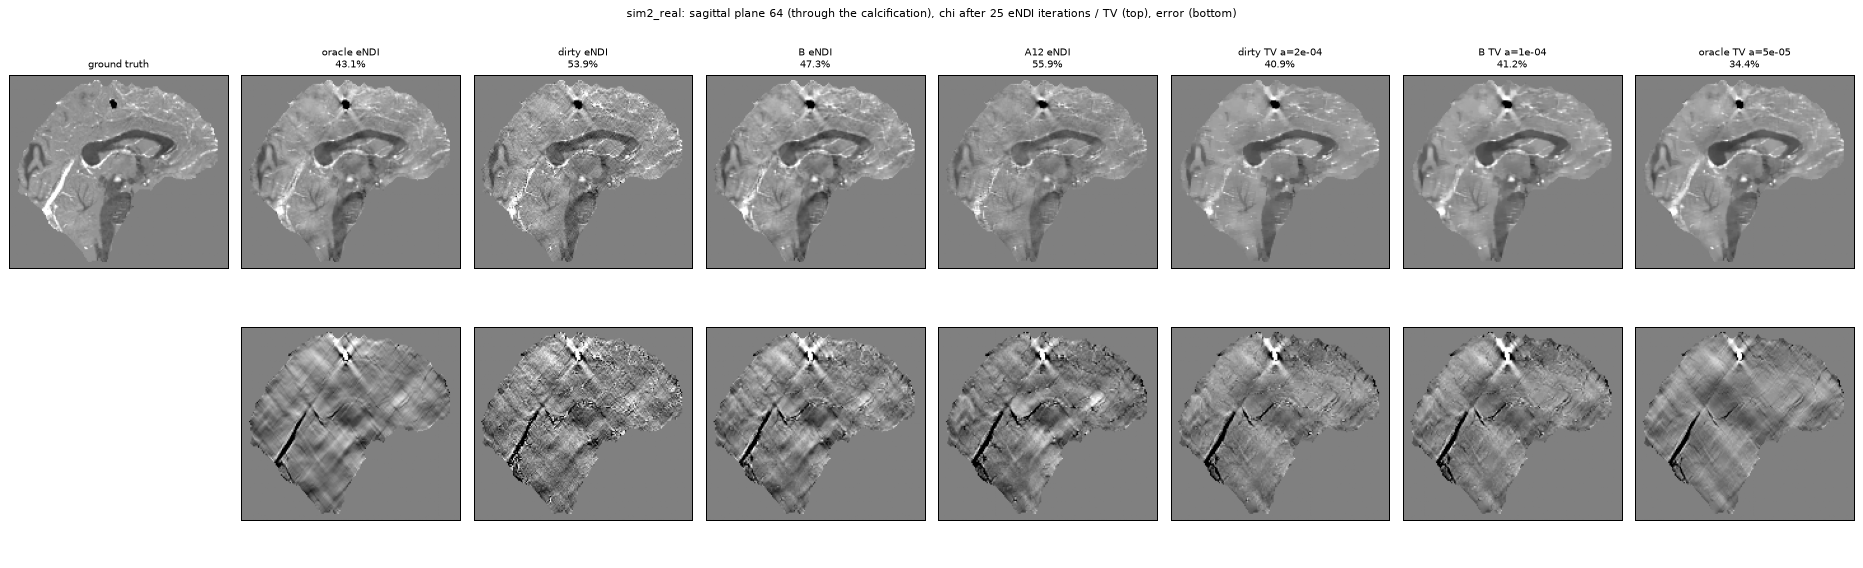

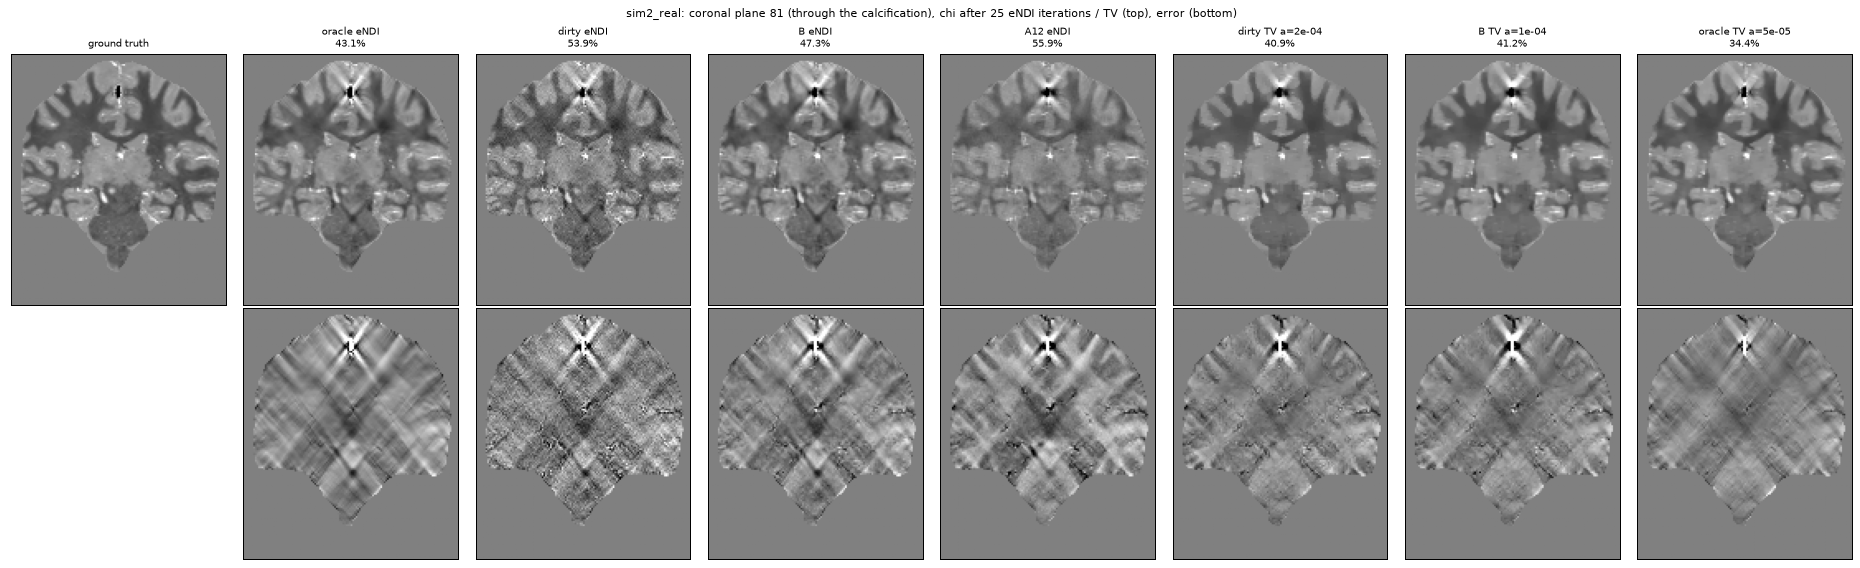

In [18]:
PLANES = ("sagittal", "coronal")
OFFSET = {"sagittal": 0, "coronal": 0}
def plane(vol, kind, idx):
    if kind == "sagittal":
        return vol[idx].T                    # (z, y)
    if kind == "coronal":
        return vol[:, idx, :].T              # (z, x)
    return vol[:, :, idx].T

def planes_montage(e, kind):
    gt, mk = gt_mask(e)
    c = np.unravel_index(np.argmax(np.abs(gt)), gt.shape)          # the calcification
    idx = int(np.clip(c[0 if kind == "sagittal" else 1] + OFFSET[kind], 0, gt.shape[0 if kind == "sagittal" else 1] - 1))
    items = []
    for lab, key in [("oracle eNDI", "oracle"), ("dirty eNDI", "dirty"), ("B eNDI", "noise_clean"), ("A12 eNDI", "A12")]:
        x = chi_map(e, key)
        if x is not None:
            items.append((lab, x))
    if TV:
        for lab, m in [("dirty TV", "tv_dirty"), ("B TV", "tv_B"), ("oracle TV", "tv_oracle")]:
            if S is not None and f"{e}__chi_{m}" in S.files:
                items.append((f"{lab} a={best[(e, m.split('_')[1])][1]:.0e}", S[f"{e}__chi_{m}"].astype(np.float32)))
    fig, ax = plt.subplots(2, len(items) + 1, figsize=(2.6 * (len(items) + 1), 6.4))
    g = plane(gt * mk, kind, idx)
    ax[0, 0].imshow(g, origin="lower", cmap="gray", vmin=CHI[0], vmax=CHI[1]); ax[0, 0].set_title("ground truth", fontsize=8); ax[1, 0].axis("off")
    for i, (lab, x) in enumerate(items, 1):
        ax[0, i].imshow(plane(x * mk, kind, idx), origin="lower", cmap="gray", vmin=CHI[0], vmax=CHI[1]); ax[0, i].set_title(f"{lab}\n{compute_rmse(x[mk], gt[mk]):.1f}%", fontsize=8)
        ax[1, i].imshow(plane((x - gt) * mk, kind, idx), origin="lower", cmap="gray", vmin=CHI_ERR[0], vmax=CHI_ERR[1])
    for a in ax.ravel():
        a.set_xticks([]); a.set_yticks([])
    fig.suptitle(f"{e}: {kind} plane {idx} (through the calcification), chi after 25 eNDI iterations / TV (top), error (bottom)", fontsize=9)
    plt.tight_layout(); show()

for kind in PLANES:
    planes_montage("sim2_real", kind)

## Verdicts (written from the numbers above)

**Claim 1 — "a 12-parameter passive Dipole-let filter beats trained networks on real residuals": TRUE against the noise-trained networks, FALSE as a blanket statement.**
* `exp7` (measured tissue residual, never used for any fit): dirty 93.60, **A12 59.15**, noise_clean 71.69, realmix_plain 61.5, gain network (GNa) 66.33. At the fixed 25 iterations the 12 numbers beat the noise network by 12.5 points, the same network trained with modelled real residuals added by 2.3, and the learned-gain network by 7.2. **Much of the gap against the noise networks is their divergence after the optimum**: at each method's own best iteration (an oracle stop that uses the ground truth) A12 is 58.86, noise_clean 61.62 (best at iteration 8, then it rises to 71.69), realmix_plain 59.47: the margins shrink to 2.8 and 0.6 points. The fixed-iteration protocol of the project is what makes the difference large; the filter's error is flat (58.9-59.2) over iterations 20-26.
* But the **joint `regime` network (56.58) is 2.6 points better than A12**, and the gain network behind `noise_clean` (GN 58.24) and AB (58.63) are within 1 point of A12. So the honest statement is: *12 fixed numbers match or beat networks of 67k-292k parameters, except the one network that has the same filter built into it*.
* `exp8` / `exp9` (in-family for the networks): A12 53.00 / 56.20 vs noise_clean 61.15 / 76.33, realmix_plain 54.1 / 64.6, regime 50.4 / 53.6.
* **On the real Sim2 (noise-like psi) the claim fails**: A12 55.93 is worse than the dirty field (53.94) and far from noise_clean (47.3-47.5 depending on the table). The filter removes cone content that is real field there (see the gate analysis); a gate (A gated 54.62) reduces but does not remove the damage.
* Limits: one RC1 head; the filter's gains were fitted on modelled residuals of that head, so `exp8`/`exp9` are not independent for either side; single seed per network.

**Claim 2 — "noise is separable by scale, real psi by angle": SUPPORTED in this data (RC1, linear, oracle-fitted gains).**
* Local SNR: for noise it varies along |k| (the field dominates below about 0.15 cycles/mm, noise above) and little along |D|; for the measured tissue, STI and off-diagonal residuals the residual dominates the cone (|D| < 0.05-0.1) at EVERY |k| and the field dominates at |D| > 0.2.
* Best gain: noise -> a function of |k|; real residuals -> a function of |D| (about 0.1 in the cone, rising through 0.4 at |D| = 0.15 to ~1 above 0.3).
* Phase NRMSE with gains that depend on one variable only: noise 26.9 (radial) vs 33.5 (angular); measured tissue 51.2 (radial) vs 45.5 (angular); STI 39.9 vs 28.2; off-diagonal 43.2 vs 36.6 (dirty: 43.6, 73.6, 45.2, 63.8). Using the wrong geometry costs: radial gains fitted on noise applied to the tissue residual give 59.0 (vs 51.2 own, 45.5 angular).
* Through the inversion (gate suite): replacing the true field in |D| < 0.2 closes 62.6 / 81.3 / 61.6% of the eNDI gap on exp7/8/9, while on noise-like Sim2 replacing |D| < 0.1 makes eNDI worse (-31%) and |k| >= 0.2 closes 57%.
* Limits: the gains are least-squares fits on the same volume (an oracle statement about the data); one head; the separation is partial (the CELL filter, both variables, is better than either alone for every residual); the measured tissue residual is one realisation; "angular" for real psi is a property of RC1's STI-type residual, and it has not been checked on in-vivo data of another scanner.

**TV headroom test (pre-registered criteria, CLAUDE.md 9bg):**
* **Criterion 1 (real Sim2) MET, strongly.** TV of the `noise_clean` output 41.20 (needed <= 45.4), eNDI of the same field 47.48. But TV of the **dirty** field is 40.86: the cleaner adds nothing once a chi prior is used (dirty -> B: 40.86 -> 41.20), and TV beats the eNDI@25 value of the cleaned field by 6.3 points. The effect does not hinge on alpha: every alpha in 5e-5 ... 5e-4 gives 40.9-46.1 for the dirty input, all below 47.48, and a single alpha = 1e-4 gives dirty 41.48 / B 41.20. XSIM agrees (TV 0.626 vs eNDI of B 0.550 on Sim2), so it is not just smoothing rewarded by NRMSE.
* **Criterion 2 (exp7, measured residual) NOT MET.** TV of A12 57.91 (needed <= 55.6) vs eNDI of A12 59.15 and AB 58.63: 1.2 points. There the 12-number filter does the work (TV of the dirty field 66.25, of B 63.78) and TV does not add a clear gain; XSIM of TV(A12) 0.319 is below eNDI of AB (0.351). For exp7-9 the best alpha of the dirty and `B` inputs is the upper edge of the grid (5e-4), so TV on those two inputs is probably under-tuned.
* **Reading rule (9bg):** only criterion 1 -> the chi prior helps the noise regime. The measured number to remember: with a chi-domain total-variation prior and no cleaning at all, Sim2 reaches 40.9 against 47.5 for cleaning + eNDI@25; the masked-field ceiling of the same TV is 34.4 (oracle input). The oracle TV on RC1 reaches 22.6 vs 35.8 for eNDI.
* Limits: alpha chosen with the ground truth, separately for RC1 (optimum 1e-4 ... 5e-4, edge for two inputs) and Sim2 (1e-4 ... 2e-4), so the TV numbers are optimistic; the eNDI baseline (alpha 1e-5, 25 iterations) was NOT tuned in the same way, so part of the gap is the inverter, not the prior; one Sim2 volume, one RC1 head, one seed.